# Generative Gaussian Mixture Classifier for Missense Variant Pathogenicity

## 1. Setup

In [1]:
import os
import time
import json
import hashlib
import platform
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
import scipy
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits
from IPython.display import display
from scipy import stats
from scipy.linalg import cholesky, solve_triangular
from scipy.special import logsumexp, expit
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             matthews_corrcoef, accuracy_score,
                             balanced_accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", category=FutureWarning)

print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| sklearn", sklearn.__version__)
print("cpu cores:", os.cpu_count())

python 3.13.15 | numpy 2.4.6 | pandas 2.3.3 | scipy 1.18.0 | sklearn 1.6.1
cpu cores: 12


In [2]:
QUICK = False              

SEED = 8
N_SPLITS = 5                # 5 folds
N_REPEATS = 3               # repeated 3 times
FEATURE_SETS = ["A", "B", "D"]
SCHEMES = ["standard", "gene_disjoint"]

K_GRID = [1, 2, 3, 4, 5]    # BIC search over 1 to 5 components
COV_TYPES = ["diag", "tied"]
N_INIT = 5                  # random starts for each EM fit
MAX_ITER = 200
TOL = 1e-4                  # convergence check on the mean log-likelihood
REG_COVAR = 1e-3            # added to the covariance diagonal (features are standardized)

N_BOOT = 2000               # gene bootstrap replicates
N_COMPARISONS = 2           # H1 compares B with A and D with A
CI_LEVEL = 1 - 0.05 / N_COMPARISONS    # Bonferroni, so 97.5% intervals
H2_CUTOFF = 0.5             # H2 is supported if new-gene gain is under half of the standard gain
TOP_GENES = [10, 25]        # for the check on very large genes
GENE_FRACTION = 1.0

if QUICK:
    N_REPEATS = 1
    N_INIT = 2
    N_BOOT = 200
    GENE_FRACTION = 0.2

N_JOBS = max(1, (os.cpu_count() or 2) - 2)
METRICS = ["roc_auc", "pr_auc", "mcc", "acc",
           "balanced_acc", "precision_pathogenic",
           "recall_pathogenic", "specificity_benign",
           "f1_pathogenic"]

OUT_DIR = Path("results_quick" if QUICK else "results")
CACHE_DIR = OUT_DIR / "cache"
FIG_DIR = OUT_DIR / "figures"
for p in (OUT_DIR, CACHE_DIR, FIG_DIR):
    p.mkdir(parents=True, exist_ok=True)

print("QUICK mode:", QUICK, "| parallel jobs:", N_JOBS, "| output folder:", OUT_DIR)

QUICK mode: False | parallel jobs: 10 | output folder: results


## 2. Load the shared dataset

In [3]:
def find_data_dir():
    for p in [Path("Dataset_preparation"), Path("."), Path("..") / "Dataset_preparation"]:
        if (p / "clinvar_expanded_model_features.csv").exists():
            return p
    raise FileNotFoundError("Could not find clinvar_expanded_model_features.csv. ")


DATA_DIR = find_data_dir()
df = pd.read_csv(DATA_DIR / "clinvar_expanded_model_features.csv")
with open(DATA_DIR / "feature_config.json") as f:
    cfg = json.load(f)

feature_sets = cfg["feature_sets"]
print("feature set sizes:", {k: len(v) for k, v in feature_sets.items()})
assert [len(feature_sets[k]) for k in FEATURE_SETS] == [6, 15, 28]
assert df["VariationID"].is_unique
assert set(df["label"].unique()) == {0, 1}
for k in FEATURE_SETS:
    assert all(c in df.columns for c in feature_sets[k])

if GENE_FRACTION < 1.0:
    rng_q = np.random.default_rng(SEED)
    all_genes = df["GeneSymbol"].unique()
    keep = rng_q.choice(all_genes, size=int(len(all_genes) * GENE_FRACTION), replace=False)
    df = df[df["GeneSymbol"].isin(keep)].reset_index(drop=True)

y_all = df["label"].to_numpy()
gene_codes, gene_names = pd.factorize(df["GeneSymbol"])
G = len(gene_names)

print("variants:", len(df), "| genes:", G)
print("pathogenic:", int(y_all.sum()), f"({y_all.mean():.1%})", "| benign:", int((1 - y_all).sum()))

gene_size = df["GeneSymbol"].value_counts()
print("largest genes:", gene_size.head(8).to_dict())
print("genes with only one variant:", int((gene_size == 1).sum()), "| median variants per gene:", gene_size.median())

missing = df[feature_sets["D"]].isna().sum()
print("features with missing values:")
display(missing[missing > 0].to_frame("n_missing").assign(percent=lambda t: (100 * t["n_missing"] / len(df)).round(1)))

const_cols = [c for c in feature_sets["D"] if df[c].nunique() <= 1]
print("constant columns:", const_cols)

feature set sizes: {'A': 6, 'B': 15, 'D': 28}
variants: 46012 | genes: 2105
pathogenic: 13999 (30.4%) | benign: 32013
largest genes: {'DNAH11': 1020, 'KMT2D': 803, 'NEB': 592, 'ADGRV1': 586, 'SACS': 495, 'DNAH5': 444, 'COL7A1': 313, 'ABCA4': 301}
genes with only one variant: 104 | median variants per gene: 10.0
features with missing values:


,n_missing,percent
gnomADe_AF,1051,2.3
gnomADe_AF_neglog10,1051,2.3
gnomADg_AF,12600,27.4
gnomADg_AF_neglog10,12600,27.4


constant columns: ['gnomAD_AF_missing']


Some gnomAD allele-frequency values, especially in gnomADg, are missing for several variants. I handled these missing values by using the median from the training data within each fold. Also, gnomAD_AF_missing has the same value for every variant, so it does not provide any variation. The standardization and covariance regularization steps handle this feature during modeling.

## 3. Folds

In [4]:
def make_folds(scheme):
    out = []
    for r in range(N_REPEATS):
        seed = SEED + r
        if scheme == "standard":
            splitter = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=seed)
            splits = splitter.split(np.zeros(len(df)), y_all)
        else:
            splitter = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=seed)
            splits = splitter.split(np.zeros(len(df)), y_all, gene_codes)
        for f, (tr, te) in enumerate(splits):
            out.append({"repeat": r, "fold": f, "train": tr, "test": te})
    return out


folds = {s: make_folds(s) for s in SCHEMES}

# fold summary: genes, variants and class balance of each fold
rows = []
for s in SCHEMES:
    for fd in folds[s]:
        tr, te = fd["train"], fd["test"]
        shared = len(set(gene_codes[tr]) & set(gene_codes[te]))
        rows.append({
            "validation": s, "repeat": fd["repeat"], "fold": fd["fold"],
            "n_train": len(tr), "n_test": len(te),
            "genes_train": len(set(gene_codes[tr])), "genes_test": len(set(gene_codes[te])),
            "genes_in_both": shared,
            "pathogenic_train": y_all[tr].mean(), "pathogenic_test": y_all[te].mean(),
        })
fold_summary = pd.DataFrame(rows)
fold_summary.to_csv(OUT_DIR / "fold_summary.csv", index=False)

# every test variant appears exactly once per repeat, and gene-disjoint folds share no gene
for s in SCHEMES:
    for r in range(N_REPEATS):
        te_all = np.concatenate([fd["test"] for fd in folds[s] if fd["repeat"] == r])
        assert len(te_all) == len(df) and len(np.unique(te_all)) == len(df)
assert (fold_summary.loc[fold_summary.validation == "gene_disjoint", "genes_in_both"] == 0).all()
print("fold checks passed")

display(fold_summary.groupby("validation")[["n_train", "n_test", "genes_train", "genes_test",
                                            "genes_in_both", "pathogenic_train", "pathogenic_test"]]
        .agg(["min", "mean", "max"]).round(3).T)

assign = []
for s in SCHEMES:
    for fd in folds[s]:
        assign.append(pd.DataFrame({
            "VariationID": df["VariationID"].to_numpy()[fd["test"]],
            "GeneSymbol": df["GeneSymbol"].to_numpy()[fd["test"]],
            "validation": s, "repeat": fd["repeat"], "test_fold": fd["fold"]}))
pd.concat(assign).to_csv(OUT_DIR / "fold_assignments.csv", index=False)

fold checks passed


validation             gene_disjoint   standard
n_train          min       35865.000  36809.000
                 mean      36809.600  36809.600
                 max       38033.000  36810.000
n_test           min        7979.000   9202.000
                 mean       9202.400   9202.400
                 max       10147.000   9203.000
genes_train      min        1670.000   2071.000
                 mean       1684.000   2077.733
                 max        1705.000   2086.000
genes_test       min         400.000   1648.000
                 mean        421.000   1661.933
                 max         435.000   1689.000
genes_in_both    min           0.000   1617.000
                 mean          0.000   1634.667
                 max           0.000   1657.000
pathogenic_train min           0.293      0.304
                 mean          0.304      0.304
                 max           0.320      0.304
pathogenic_test  min           0.247      0.304
                 mean          0.305      0.304
                 max           0.350      0.304

## 4. EM for a Gaussian mixture in NumPy

For each class, EM estimates a mixture with \(K\) Gaussian components. In the E-step, the model calculates how likely each variant is to belong to each component. In the M-step, it updates the component weights, means, and covariance matrices using these probabilities.

The BIC search tests two covariance types:
- Diagonal covariance: each component has its own diagonal covariance matrix.
- Tied covariance: all components within a class share one full covariance matrix.
The model starts with k-means++ initialization and hard cluster assignments. A small regularization value is added to the covariance diagonals to keep the matrices stable and invertible because some features are highly correlated. The algorithm stops when the mean log-likelihood changes very little or when it reaches the maximum number of iterations.

In [5]:
LOG2PI = np.log(2 * np.pi)
EPS = np.finfo(float).eps


def log_prob_components(X, weights, means, cov, cov_type):
    # returns an n x K matrix with log(weight_k) + log N(x | mean_k, cov_k)
    n, d = X.shape
    K = len(weights)
    if cov_type == "diag":
        prec = 1.0 / cov                                   # K x d
        maha = (X ** 2) @ prec.T - 2 * X @ (means * prec).T + np.sum(means ** 2 * prec, axis=1)
        logdet = np.sum(np.log(cov), axis=1)
    else:
        L = cholesky(cov, lower=True)                      # cov is d x d, shared by all components
        Xw = solve_triangular(L, X.T, lower=True).T
        Mw = solve_triangular(L, means.T, lower=True).T
        maha = (Xw ** 2).sum(1)[:, None] - 2 * Xw @ Mw.T + (Mw ** 2).sum(1)[None, :]
        logdet = np.full(K, 2 * np.sum(np.log(np.diag(L))))
    maha = np.maximum(maha, 0.0)
    return np.log(weights) - 0.5 * (d * LOG2PI + logdet + maha)


def m_step(X, resp, reg, cov_type):
    n, d = X.shape
    nk = resp.sum(0) + 10 * EPS
    weighted_sum = resp.T @ X
    means = weighted_sum / nk[:, None]
    weights = nk / n
    if cov_type == "diag":
        avg_x2 = (resp.T @ (X * X)) / nk[:, None]
        cov = avg_x2 - 2 * means * weighted_sum / nk[:, None] + means ** 2 + reg
    else:
        cov = (X.T @ X - (nk[:, None] * means).T @ means) / nk.sum()
        cov = (cov + cov.T) / 2
        cov.flat[:: d + 1] += reg
    return weights, means, cov


def kmeanspp_resp(X, K, rng):
    # k-means++ seeding, then every point goes to its nearest seed
    n = X.shape[0]
    if K == 1:
        return np.ones((n, 1))
    idx = [int(rng.integers(n))]
    d2 = ((X - X[idx[0]]) ** 2).sum(1)
    for _ in range(1, K):
        total = d2.sum()
        nxt = int(rng.choice(n, p=d2 / total)) if total > 0 else int(rng.integers(n))
        idx.append(nxt)
        d2 = np.minimum(d2, ((X - X[nxt]) ** 2).sum(1))
    C = X[idx]
    dist = (X ** 2).sum(1)[:, None] - 2 * X @ C.T + (C ** 2).sum(1)[None, :]
    lab = dist.argmin(1)
    for k in range(K):                       # make sure no component starts empty
        if not np.any(lab == k):
            lab[int(rng.integers(n))] = k
    resp = np.zeros((n, K))
    resp[np.arange(n), lab] = 1.0
    return resp


def fit_em(X, K, cov_type, rng, reg=None, max_iter=None, tol=None, init=None):
    reg = REG_COVAR if reg is None else reg
    max_iter = MAX_ITER if max_iter is None else max_iter
    tol = TOL if tol is None else tol
    if init is None:
        weights, means, cov = m_step(X, kmeanspp_resp(X, K, rng), reg, cov_type)
    else:
        weights, means, cov = init
    prev = -np.inf
    converged = False
    n_iter = 0
    for n_iter in range(1, max_iter + 1):
        lp = log_prob_components(X, weights, means, cov, cov_type)       # E-step
        lse = logsumexp(lp, axis=1)
        ll = lse.mean()
        resp = np.exp(lp - lse[:, None])
        weights, means, cov = m_step(X, resp, reg, cov_type)             # M-step
        if abs(ll - prev) < tol:
            converged = True
            break
        prev = ll
    final_ll = logsumexp(log_prob_components(X, weights, means, cov, cov_type), axis=1).mean()
    return {"weights": weights, "means": means, "cov": cov, "ll": final_ll,
            "n_iter": n_iter, "converged": converged}


def n_params(K, d, cov_type):
    cov_p = K * d if cov_type == "diag" else d * (d + 1) // 2
    return K * d + cov_p + (K - 1)


def fit_mixture(X, K, cov_type, seed_parts, n_init=None, reg=None):
    # several random starts, keep the one with the best log-likelihood
    n_init = N_INIT if n_init is None else n_init
    n_starts = 1 if K == 1 else n_init       # with one component all starts are the same
    children = np.random.SeedSequence(seed_parts).spawn(n_starts)
    fits = [fit_em(X, K, cov_type, np.random.default_rng(s), reg=reg) for s in children]
    lls = np.array([f["ll"] for f in fits])
    best = fits[int(lls.argmax())]
    info = {"ll": best["ll"], "n_iter": best["n_iter"], "converged": best["converged"],
            "n_starts": n_starts, "n_converged_starts": int(sum(f["converged"] for f in fits)),
            "ll_range": float(lls.max() - lls.min())}
    return best, info


def mixture_logpdf(X, model, cov_type):
    lp = log_prob_components(X, model["weights"], model["means"], model["cov"], cov_type)
    return logsumexp(lp, axis=1)


# step 1 of the method: one Gaussian per class (full covariance) as the simple generative baseline
def fit_one_gaussian(X, reg=None):
    reg = REG_COVAR if reg is None else reg
    mu = X.mean(0)
    Xc = X - mu
    cov = Xc.T @ Xc / len(X)
    cov.flat[:: X.shape[1] + 1] += reg
    return mu, cov


def one_gaussian_logpdf(X, mu, cov):
    d = X.shape[1]
    L = cholesky(cov, lower=True)
    z = solve_triangular(L, (X - mu).T, lower=True)
    return -0.5 * (d * LOG2PI + 2 * np.sum(np.log(np.diag(L))) + (z ** 2).sum(0))

### Check against scikit learn

I verified my EM implementation against scikit learn’s GaussianMixture using the same initialization, tolerance, iteration limit, and regularization. Both implementations produced matching log likelihoods, means, and BIC values for the tested feature sets and covariance structures.

In [6]:
def preprocess(Xtr, Xte):
    med = np.nanmedian(Xtr, axis=0)
    med = np.where(np.isnan(med), 0.0, med)
    Xtr = np.where(np.isnan(Xtr), med, Xtr)
    Xte = np.where(np.isnan(Xte), med, Xte)
    mu = Xtr.mean(0)
    sd = Xtr.std(0)
    sd[sd < 1e-12] = 1.0                      # constant columns stay at zero
    return (Xtr - mu) / sd, (Xte - mu) / sd


check_rows = []
for fs in ["A", "D"]:
    Xfs = df[feature_sets[fs]].to_numpy(dtype=float)
    Xs, _ = preprocess(Xfs, Xfs[:5])
    Xc = Xs[y_all == 1]
    for cov_type, K in [("diag", 1), ("diag", 3), ("tied", 1), ("tied", 3), ("tied", 4)]:
        rng = np.random.default_rng(123)
        init = m_step(Xc, kmeanspp_resp(Xc, K, rng), REG_COVAR, cov_type)
        mine = fit_em(Xc, K, cov_type, rng, init=init)
        w0, m0, c0 = init
        p0 = 1.0 / c0 if cov_type == "diag" else np.linalg.inv(c0)
        gm = GaussianMixture(n_components=K, covariance_type=cov_type, weights_init=w0, means_init=m0,
                             precisions_init=p0, reg_covar=REG_COVAR, tol=TOL, max_iter=MAX_ITER,
                             n_init=1).fit(Xc)
        my_bic = -2 * mine["ll"] * len(Xc) + n_params(K, Xc.shape[1], cov_type) * np.log(len(Xc))
        check_rows.append({
            "set": fs, "cov": cov_type, "K": K,
            "loglik_mine": mine["ll"], "loglik_sklearn": gm.score(Xc),
            "abs_diff_loglik": abs(mine["ll"] - gm.score(Xc)),
            "max_abs_diff_means": np.abs(mine["means"] - gm.means_).max(),
            "abs_diff_bic": abs(my_bic - gm.bic(Xc)),
            "iter_mine": mine["n_iter"], "iter_sklearn": gm.n_iter_})

check = pd.DataFrame(check_rows)
display(check.round(8))
assert (check["abs_diff_loglik"] < 1e-6).all() and (check["abs_diff_bic"] < 1e-2).all()
assert (check["max_abs_diff_means"] < 1e-4).all()

# one Gaussian with full covariance against sklearn
for fs in ["A", "D"]:
    Xfs = df[feature_sets[fs]].to_numpy(dtype=float)
    Xs, _ = preprocess(Xfs, Xfs[:5])
    Xc = Xs[y_all == 0]
    mu, cov = fit_one_gaussian(Xc)
    gm = GaussianMixture(1, covariance_type="full", reg_covar=REG_COVAR).fit(Xc)
    assert abs(one_gaussian_logpdf(Xc, mu, cov).mean() - gm.score(Xc)) < 1e-6
print("EM and one-component Gaussian agree with scikit-learn")

,set,cov,K,loglik_mine,loglik_sklearn,abs_diff_loglik,max_abs_diff_means,abs_diff_bic,iter_mine,iter_sklearn
0,A,diag,1,-5.406914,-5.406914,0.0,0.0,0.0,2,2
1,A,diag,3,2.041896,2.041896,0.0,0.0,0.0,30,30
2,A,tied,1,-4.412301,-4.412301,0.0,0.0,0.0,2,2
3,A,tied,3,-2.886454,-2.886454,0.0,0.0,0.0,20,20
4,A,tied,4,-2.603505,-2.603505,0.0,0.0,0.0,10,10
5,D,diag,1,-27.571081,-27.571081,0.0,0.0,0.0,2,2
6,D,diag,3,-13.249566,-13.249566,0.0,0.0,0.0,15,15
7,D,tied,1,-15.914130,-15.914130,0.0,0.0,0.0,2,2
8,D,tied,3,-14.236529,-14.236529,0.0,0.0,0.0,14,14
9,D,tied,4,-13.655791,-13.655791,0.0,0.0,0.0,13,13


EM and one-component Gaussian agree with scikit-learn


## 5. One fold from start to end

For each fold and feature set, I first impute missing values and standardize the features using only the training data. Then, for each class, I test diagonal and tied covariance structures with 1 to 5 components and select the model with the lowest training BIC.

The class priors are also calculated from the training fold. Held-out variants are then scored using the class likelihoods and priors. A positive score indicates a pathogenic prediction. The one-component baseline follows the same process without BIC search.

I also save BIC values, convergence results, variation across random starts, fitting times, and scores for fixed covariance and component settings.

In [7]:
def get_metrics(y, score, threshold=0.0):
    pred = (score > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "roc_auc": roc_auc_score(y, score),
        "pr_auc": average_precision_score(y, score),
        "mcc": matthews_corrcoef(y, pred),
        "acc": accuracy_score(y, pred),
        "balanced_acc": balanced_accuracy_score(y, pred),
        "precision_pathogenic": precision_score(y, pred, pos_label=1, zero_division=0),
        "recall_pathogenic": recall_score(y, pred, pos_label=1, zero_division=0),
        "specificity_benign": tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        "f1_pathogenic": f1_score(y, pred, pos_label=1, zero_division=0),
        "true_benign": tn, "false_pathogenic": fp,
        "false_benign": fn, "true_pathogenic": tp
    }


def run_fold_inner(job):
    t_start = time.time()
    X, y, tr, te = job["X"], job["y"], job["train"], job["test"]
    Xtr, Xte = preprocess(X[tr], X[te])
    ytr, yte = y[tr], y[te]
    d = Xtr.shape[1]

    prior1 = ytr.mean()                                    # priors from the training fold only
    log_prior_ratio = np.log(prior1 / (1 - prior1))

    test_ll = {}
    bic_rows = []
    for c in (0, 1):
        Xc = Xtr[ytr == c]
        for ci, cov_type in enumerate(COV_TYPES):
            for K in K_GRID:
                t0 = time.time()
                best, info = fit_mixture(Xc, K, cov_type, [SEED, job["scheme_id"], job["fs_id"],
                                                           job["repeat"], job["fold"], c, ci, K])
                secs = time.time() - t0
                npar = n_params(K, d, cov_type)
                bic = -2 * info["ll"] * len(Xc) + npar * np.log(len(Xc))     # computed on training rows
                test_ll[(c, cov_type, K)] = mixture_logpdf(Xte, best, cov_type)
                bic_rows.append({"cls": c, "cov": cov_type, "K": K, "n_class_train": len(Xc),
                                 "n_params": npar, "loglik_mean": info["ll"], "bic": bic,
                                 "n_iter": info["n_iter"], "converged": info["converged"],
                                 "n_starts": info["n_starts"],
                                 "n_converged_starts": info["n_converged_starts"],
                                 "ll_range": info["ll_range"], "seconds": secs, "selected": False})
    bic_df = pd.DataFrame(bic_rows)

    # BIC choice for each class on its own
    sel = {}
    for c in (0, 1):
        sub = bic_df[bic_df["cls"] == c]
        i = sub["bic"].idxmin()
        bic_df.loc[i, "selected"] = True
        sel[c] = (bic_df.loc[i, "cov"], int(bic_df.loc[i, "K"]))
    score_mix = test_ll[(1,) + sel[1]] - test_ll[(0,) + sel[0]] + log_prior_ratio

    fixed = []
    for cov_type in COV_TYPES:
        for K in K_GRID:
            s = test_ll[(1, cov_type, K)] - test_ll[(0, cov_type, K)] + log_prior_ratio
            fixed.append({"cov": cov_type, "K": K, **get_metrics(yte, s)})

    # one-component Gaussian per class
    ll_one = []
    for c in (0, 1):
        mu, cov = fit_one_gaussian(Xtr[ytr == c])
        ll_one.append(one_gaussian_logpdf(Xte, mu, cov))
    score_one = ll_one[1] - ll_one[0] + log_prior_ratio

    return {"scheme": job["scheme"], "fs": job["fs"], "repeat": job["repeat"], "fold": job["fold"],
            "test_idx": te, "y_test": yte, "score_mix": score_mix, "score_one": score_one,
            "bic": bic_df, "fixed": pd.DataFrame(fixed), "sel0": sel[0], "sel1": sel[1],
            "n_train": len(tr), "n_test": len(te), "prior1": prior1,
            "seconds": time.time() - t_start}

SETTINGS_TAG = hashlib.md5(json.dumps([SEED, N_SPLITS, N_REPEATS, K_GRID, COV_TYPES, N_INIT, MAX_ITER, TOL,
                                       REG_COVAR, len(df), GENE_FRACTION]).encode()).hexdigest()[:8]


def run_fold(job):
    cache_file = CACHE_DIR / f"{SETTINGS_TAG}_{job['scheme']}_{job['fs']}_r{job['repeat']}_f{job['fold']}.pkl"
    if cache_file.exists():
        return joblib.load(cache_file)
    with threadpool_limits(limits=1):         # one BLAS thread per worker, the workers run in parallel
        out = run_fold_inner(job)
    joblib.dump(out, cache_file)
    return out

I first ran one fold to check how long it took and make sure the results looked reasonable before running the complete experiment.

In [8]:
X_sets = {fs: df[feature_sets[fs]].to_numpy(dtype=float) for fs in FEATURE_SETS}


def make_job(scheme, fs, fd):
    return {"scheme": scheme, "scheme_id": SCHEMES.index(scheme), "fs": fs,
            "fs_id": FEATURE_SETS.index(fs), "repeat": fd["repeat"], "fold": fd["fold"],
            "X": X_sets[fs], "y": y_all, "train": fd["train"], "test": fd["test"]}


t0 = time.time()
with threadpool_limits(limits=1):
    test_out = run_fold_inner(make_job("gene_disjoint", "A", folds["gene_disjoint"][0]))
print(f"one fold, set A, gene-disjoint: {time.time() - t0:.1f} seconds")
print("BIC choice benign:", test_out["sel0"], "| pathogenic:", test_out["sel1"])
print({k: round(v, 3) for k, v in get_metrics(test_out["y_test"], test_out["score_mix"]).items()})
display(test_out["bic"].round(3).head(10))

one fold, set A, gene-disjoint: 4.1 seconds
BIC choice benign: ('diag', 5) | pathogenic: ('diag', 5)
{'roc_auc': np.float64(0.796), 'pr_auc': np.float64(0.634), 'mcc': np.float64(0.45), 'acc': 0.75, 'balanced_acc': np.float64(0.728), 'precision_pathogenic': 0.623, 'recall_pathogenic': 0.66, 'specificity_benign': np.float64(0.796), 'f1_pathogenic': 0.641, 'true_benign': np.int64(4793), 'false_pathogenic': np.int64(1227), 'false_benign': np.int64(1045), 'true_pathogenic': np.int64(2027)}


,cls,cov,K,n_class_train,n_params,loglik_mean,bic,n_iter,converged,n_starts,n_converged_starts,ll_range,seconds,selected
0,0,diag,1,25993,12,-8.781,456589.394,2,True,1,1,0.000,0.009,False
1,0,diag,2,25993,25,-3.690,192077.441,16,True,5,5,0.219,0.268,False
2,0,diag,3,25993,38,-2.442,127318.850,27,True,5,5,0.519,0.294,False
3,0,diag,4,25993,51,-1.878,98156.833,19,True,5,5,0.792,0.505,False
4,0,diag,5,25993,64,-1.319,69201.332,25,True,5,5,0.445,0.582,True
5,0,tied,1,25993,27,-7.081,368372.033,2,True,1,1,0.000,0.004,False
6,0,tied,2,25993,34,-5.924,308300.002,6,True,5,5,0.000,0.161,False
7,0,tied,3,25993,41,-5.729,298255.442,6,True,5,5,0.227,0.224,False
8,0,tied,4,25993,48,-5.573,290191.248,16,True,5,5,0.123,0.370,False
9,0,tied,5,25993,55,-4.877,254078.173,18,True,5,5,0.676,0.329,False


## 6. Run all folds

In [9]:
jobs = [make_job(s, fs, fd) for s in SCHEMES for fs in FEATURE_SETS for fd in folds[s]]
print("fold runs:", len(jobs), "| already saved:", len(list(CACHE_DIR.glob(f"{SETTINGS_TAG}_*.pkl"))))

t_all = time.time()
out_list = Parallel(n_jobs=N_JOBS, verbose=5)(delayed(run_fold)(j) for j in jobs)
wall_seconds = time.time() - t_all
results = {(r["scheme"], r["fs"], r["repeat"], r["fold"]): r for r in out_list}
print(f"done, wall time of this run: {wall_seconds / 60:.1f} minutes")

fold runs: 90 | already saved: 90


[Parallel(n_jobs=10)]: Using backend LokyBackend with 10 concurrent workers.


done, wall time of this run: 0.0 minutes


[Parallel(n_jobs=10)]: Done  90 out of  90 | elapsed:    1.5s finished


## 7. results

In [10]:
MODELS = {"gmm_bic": "score_mix", "gauss_1comp": "score_one"}

metric_rows = []
for (scheme, fs, r, f), res in results.items():
    for model, key in MODELS.items():
        m = get_metrics(res["y_test"], res[key])
        metric_rows.append({"validation": scheme, "feature_set": fs, "repeat": r, "fold": f,
                            "model": model, "n_test": res["n_test"], **m})
metrics_df = (pd.DataFrame(metric_rows)
              .sort_values(["validation", "model", "feature_set", "repeat", "fold"]).reset_index(drop=True))
metrics_df.to_csv(OUT_DIR / "metrics_by_fold.csv", index=False)

pred_parts = []
vid = df["VariationID"].to_numpy()
gsym = df["GeneSymbol"].to_numpy()
for (scheme, fs, r, f), res in results.items():
    for model, key in MODELS.items():
        s = res[key]
        pred_parts.append(pd.DataFrame({
            "model": model, "feature_set": fs, "validation": scheme, "repeat": r, "fold": f,
            "VariationID": vid[res["test_idx"]], "GeneSymbol": gsym[res["test_idx"]],
            "label": res["y_test"], "log_odds": s, "p_pathogenic": expit(s),
            "pred_label": (s > 0).astype(int)}))
predictions = pd.concat(pred_parts, ignore_index=True)
predictions.to_csv(OUT_DIR / "predictions_gmm.csv.gz", index=False, compression="gzip")
print("saved predictions:", predictions.shape)

# BIC records with chosen settings and convergence status
bic_parts = []
for (scheme, fs, r, f), res in results.items():
    bic_parts.append(res["bic"].assign(validation=scheme, feature_set=fs, repeat=r, fold=f))
bic_all = pd.concat(bic_parts, ignore_index=True)
bic_all["class"] = bic_all["cls"].map({0: "benign", 1: "pathogenic"})
bic_all.to_csv(OUT_DIR / "bic_records.csv", index=False)
chosen = bic_all[bic_all["selected"]].copy()
chosen.to_csv(OUT_DIR / "selected_settings.csv", index=False)

# fixed (cov, K) results
fixed_parts = []
for (scheme, fs, r, f), res in results.items():
    fixed_parts.append(res["fixed"].assign(validation=scheme, feature_set=fs, repeat=r, fold=f))
fixed_df = pd.concat(fixed_parts, ignore_index=True)
fixed_df.to_csv(OUT_DIR / "fixed_setting_metrics.csv", index=False)

run_info = pd.DataFrame([{"validation": k[0], "feature_set": k[1], "repeat": k[2], "fold": k[3],
                          "seconds": v["seconds"], "n_train": v["n_train"], "n_test": v["n_test"]}
                         for k, v in results.items()])
run_info.to_csv(OUT_DIR / "runtime_by_fold.csv", index=False)

saved predictions: (1656432, 11)


## 8. Main results: standard folds vs gene-disjoint folds

In [11]:
def mean_sd_table(m, cols=METRICS):
    g = m.groupby(["validation", "model", "feature_set"])[cols]
    mean, sd = g.mean(), g.std()
    return mean.round(3).astype(str) + " +/- " + sd.round(3).astype(str)


print(f"majority class floor: accuracy {1 - y_all.mean():.3f}, MCC 0, PR-AUC {y_all.mean():.3f}")
main_table = mean_sd_table(metrics_df)
main_table.to_csv(OUT_DIR / "main_results.csv")
display(main_table)

majority class floor: accuracy 0.696, MCC 0, PR-AUC 0.304


roc_auc           pr_auc              mcc              acc     balanced_acc precision_pathogenic recall_pathogenic specificity_benign    f1_pathogenic
validation    model       feature_set                                                                                                                                                                
gene_disjoint gauss_1comp A            0.796 +/- 0.012  0.588 +/- 0.045  0.371 +/- 0.025  0.617 +/- 0.025   0.696 +/- 0.01      0.437 +/- 0.043    0.897 +/- 0.01    0.494 +/- 0.023  0.587 +/- 0.039
                          B            0.845 +/- 0.011   0.665 +/- 0.05  0.434 +/- 0.036  0.654 +/- 0.031  0.731 +/- 0.014       0.467 +/- 0.05   0.925 +/- 0.009     0.537 +/- 0.03  0.619 +/- 0.045
                          D            0.863 +/- 0.012  0.689 +/- 0.053  0.476 +/- 0.034  0.691 +/- 0.028  0.756 +/- 0.012      0.497 +/- 0.051   0.923 +/- 0.008     0.59 +/- 0.028  0.644 +/- 0.043
              gmm_bic     A             0.759 +/- 0.02  0.541 +/- 0.052  0.348 +/- 0.058  0.688 +/- 0.046  0.685 +/- 0.025      0.499 +/- 0.074   0.673 +/- 0.037    0.696 +/- 0.077  0.569 +/- 0.043
                          B            0.823 +/- 0.023  0.657 +/- 0.054  0.439 +/- 0.044  0.677 +/- 0.039  0.736 +/- 0.019      0.487 +/- 0.061   0.885 +/- 0.042     0.588 +/- 0.06  0.625 +/- 0.047
                          D            0.837 +/- 0.018  0.662 +/- 0.061  0.473 +/- 0.042  0.722 +/- 0.036  0.755 +/- 0.019       0.53 +/- 0.058   0.843 +/- 0.045    0.668 +/- 0.066  0.648 +/- 0.042
standard      gauss_1comp A            0.797 +/- 0.005   0.59 +/- 0.006  0.371 +/- 0.007  0.616 +/- 0.004  0.695 +/- 0.004      0.436 +/- 0.003   0.897 +/- 0.005    0.493 +/- 0.006  0.587 +/- 0.004
                          B            0.845 +/- 0.003  0.666 +/- 0.006  0.433 +/- 0.006  0.653 +/- 0.004   0.73 +/- 0.004      0.465 +/- 0.003   0.925 +/- 0.004    0.535 +/- 0.006  0.619 +/- 0.003
                          D            0.863 +/- 0.003   0.69 +/- 0.007  0.475 +/- 0.005  0.691 +/- 0.004  0.756 +/- 0.003      0.496 +/- 0.003   0.923 +/- 0.004    0.589 +/- 0.006  0.645 +/- 0.003
              gmm_bic     A            0.774 +/- 0.017  0.554 +/- 0.024  0.397 +/- 0.035  0.729 +/- 0.028  0.706 +/- 0.016       0.55 +/- 0.041   0.647 +/- 0.041    0.765 +/- 0.053  0.593 +/- 0.018
                          B             0.83 +/- 0.012  0.667 +/- 0.019  0.432 +/- 0.015  0.668 +/- 0.031  0.731 +/- 0.012      0.478 +/- 0.024   0.892 +/- 0.042     0.57 +/- 0.062  0.621 +/- 0.012
                          D            0.823 +/- 0.017  0.636 +/- 0.028  0.453 +/- 0.048  0.732 +/- 0.025  0.743 +/- 0.027      0.544 +/- 0.035   0.772 +/- 0.074     0.714 +/- 0.05  0.636 +/- 0.033

### Drop on unseen genes

I evaluated the same model and feature set using both standard folds and gene-disjoint folds. I calculated the drop as the standard-fold score minus the gene-disjoint score. The PR-AUC interval was obtained using the gene bootstrap.

In [12]:
means = metrics_df.groupby(["model", "feature_set", "validation"])[METRICS].mean()
drop_rows = []
for (model, fs), _ in means.groupby(level=[0, 1]):
    std_m = means.loc[(model, fs, "standard")]
    gen_m = means.loc[(model, fs, "gene_disjoint")]
    row = {"model": model, "feature_set": fs}
    for m in METRICS:
        row[f"{m}_standard"] = std_m[m]
        row[f"{m}_gene_disjoint"] = gen_m[m]
        row[f"{m}_drop"] = std_m[m] - gen_m[m]
    drop_rows.append(row)
drop_table = pd.DataFrame(drop_rows)
drop_table.to_csv(OUT_DIR / "performance_drop.csv", index=False)
display(drop_table.round(3))

# spread over the three repeats
rep = (metrics_df[metrics_df.model == "gmm_bic"]
       .groupby(["validation", "feature_set", "repeat"])["pr_auc"].mean().unstack("repeat").round(3))
print("PR-AUC of the BIC mixture for each repeat (mean over its 5 folds):")
display(rep)

,model,feature_set,roc_auc_standard,roc_auc_gene_disjoint,roc_auc_drop,pr_auc_standard,pr_auc_gene_disjoint,pr_auc_drop,mcc_standard,mcc_gene_disjoint,mcc_drop,acc_standard,acc_gene_disjoint,acc_drop,balanced_acc_standard,balanced_acc_gene_disjoint,balanced_acc_drop,precision_pathogenic_standard,precision_pathogenic_gene_disjoint,precision_pathogenic_drop,recall_pathogenic_standard,recall_pathogenic_gene_disjoint,recall_pathogenic_drop,specificity_benign_standard,specificity_benign_gene_disjoint,specificity_benign_drop,f1_pathogenic_standard,f1_pathogenic_gene_disjoint,f1_pathogenic_drop
0,gauss_1comp,A,0.797,0.796,0.001,0.590,0.588,0.002,0.371,0.371,-0.000,0.616,0.617,-0.000,0.695,0.696,-0.000,0.436,0.437,-0.001,0.897,0.897,0.000,0.493,0.494,-0.001,0.587,0.587,0.001
1,gauss_1comp,B,0.845,0.845,-0.000,0.666,0.665,0.001,0.433,0.434,-0.002,0.653,0.654,-0.001,0.730,0.731,-0.001,0.465,0.467,-0.002,0.925,0.925,0.000,0.535,0.537,-0.002,0.619,0.619,0.000
2,gauss_1comp,D,0.863,0.863,0.000,0.690,0.689,0.001,0.475,0.476,-0.001,0.691,0.691,-0.000,0.756,0.756,-0.000,0.496,0.497,-0.001,0.923,0.923,0.000,0.589,0.590,-0.001,0.645,0.644,0.001
3,gmm_bic,A,0.774,0.759,0.016,0.554,0.541,0.013,0.397,0.348,0.049,0.729,0.688,0.041,0.706,0.685,0.021,0.550,0.499,0.051,0.647,0.673,-0.026,0.765,0.696,0.068,0.593,0.569,0.024
4,gmm_bic,B,0.830,0.823,0.007,0.667,0.657,0.010,0.432,0.439,-0.007,0.668,0.677,-0.009,0.731,0.736,-0.005,0.478,0.487,-0.009,0.892,0.885,0.007,0.570,0.588,-0.018,0.621,0.625,-0.004
5,gmm_bic,D,0.823,0.837,-0.014,0.636,0.662,-0.026,0.453,0.473,-0.020,0.732,0.722,0.010,0.743,0.755,-0.012,0.544,0.530,0.014,0.772,0.843,-0.071,0.714,0.668,0.046,0.636,0.648,-0.012


PR-AUC of the BIC mixture for each repeat (mean over its 5 folds):


repeat                         0      1      2
validation    feature_set                     
gene_disjoint A            0.549  0.529  0.544
              B            0.667  0.666  0.639
              D            0.660  0.643  0.682
standard      A            0.555  0.544  0.563
              B            0.676  0.654  0.670
              D            0.642  0.635  0.630

## 9. BIC choices, stability and runtime

BIC selections. I recorded how often each component number and covariance type were selected for each class, feature set, and validation scheme across the 15 folds.

In [13]:
for lab, col in [("number of components K", "K"), ("covariance type", "cov")]:
    tab = pd.crosstab([chosen["validation"], chosen["feature_set"], chosen["class"]], chosen[col])
    print("Chosen", lab)
    display(tab)
    tab.to_csv(OUT_DIR / f"chosen_{col}.csv")

Chosen number of components K


K                                     3  4   5
validation    feature_set class               
gene_disjoint A           benign      0  0  15
                          pathogenic  0  1  14
              B           benign      0  0  15
                          pathogenic  0  0  15
              D           benign      3  2  10
                          pathogenic  0  0  15
standard      A           benign      0  1  14
                          pathogenic  0  0  15
              B           benign      0  0  15
                          pathogenic  0  0  15
              D           benign      0  2  13
                          pathogenic  0  0  15

Chosen covariance type


cov                                   diag  tied
validation    feature_set class                 
gene_disjoint A           benign        15     0
                          pathogenic    15     0
              B           benign        15     0
                          pathogenic    15     0
              D           benign         6     9
                          pathogenic    13     2
standard      A           benign        15     0
                          pathogenic    15     0
              B           benign        15     0
                          pathogenic    15     0
              D           benign        10     5
                          pathogenic    13     2

***EM stability***. For each fit, I recorded the log-likelihood from every random start. ll_range is the difference between the best and worst result. A larger value means the starts reached different local solutions. A convergence failure means the model reached the iteration limit before stabilizing.

In [14]:
b = bic_all.copy()
b["best_converged"] = b["converged"]
b["all_starts_converged"] = b["n_converged_starts"] == b["n_starts"]
b["starts_disagree"] = (b["ll_range"] > 1e-3) & (b["n_starts"] > 1)

print("fits in total:", len(b), "| best start did not converge:", int((~b["best_converged"]).sum()),
      f"({100 * (~b['best_converged']).mean():.2f}%)")
print("among the BIC-selected fits, not converged:", int((~chosen["converged"]).sum()), "of", len(chosen))

stab = (b[b["K"] > 1].groupby(["feature_set", "cov", "K"])
        .agg(best_converged=("best_converged", "mean"), all_starts_converged=("all_starts_converged", "mean"),
             starts_disagree=("starts_disagree", "mean"), median_ll_range=("ll_range", "median"),
             median_iterations=("n_iter", "median")).round(3))
stab.to_csv(OUT_DIR / "stability_summary.csv")
display(stab)

# convergence failures per validation scheme and set
fail = b.groupby(["validation", "feature_set"])["best_converged"].apply(lambda s: int((~s).sum())).to_frame("not_converged")
display(fail.T)

fits in total: 1800 | best start did not converge: 0 (0.00%)
among the BIC-selected fits, not converged: 0 of 180


best_converged  all_starts_converged  starts_disagree  median_ll_range  median_iterations
feature_set cov  K                                                                                           
A           diag 2             1.0                 1.000            0.317            0.000               10.0
                 3             1.0                 1.000            0.917            0.564               25.0
                 4             1.0                 1.000            1.000            0.474               26.5
                 5             1.0                 1.000            1.000            0.458               31.0
            tied 2             1.0                 1.000            0.900            0.977                6.0
                 3             1.0                 1.000            1.000            0.735                8.0
                 4             1.0                 1.000            1.000            0.649               12.0
                 5             1.0                 1.000            1.000            0.677               14.0
B           diag 2             1.0                 1.000            1.000            3.199               13.0
                 3             1.0                 1.000            1.000            2.631               18.0
                 4             1.0                 1.000            1.000            2.353               23.0
                 5             1.0                 0.983            1.000            2.139               21.5
            tied 2             1.0                 1.000            1.000            3.136                3.0
                 3             1.0                 1.000            1.000            3.376                9.0
                 4             1.0                 1.000            1.000            3.791               14.5
                 5             1.0                 1.000            1.000            3.676               18.0
D           diag 2             1.0                 1.000            0.967            2.749               16.0
                 3             1.0                 1.000            1.000            3.155               20.0
                 4             1.0                 1.000            1.000            3.294               26.0
                 5             1.0                 1.000            1.000            3.556               29.5
            tied 2             1.0                 1.000            1.000            3.034                7.0
                 3             1.0                 1.000            1.000            3.492               12.0
                 4             1.0                 1.000            1.000            3.553               15.0
                 5             1.0                 1.000            1.000            3.515               14.0

validation    gene_disjoint       standard      
feature_set               A  B  D        A  B  D
not_converged             0  0  0        0  0  0

In [15]:
rt = run_info.groupby(["validation", "feature_set"])["seconds"].agg(["mean", "max"]).round(1)
display(rt)
print(f"sum of all fold times: {run_info['seconds'].sum() / 3600:.2f} hours (single core equivalent)")
fit_time = bic_all.groupby(["cov", "K"])["seconds"].mean().unstack("cov").round(2)
print("average seconds for one fit (all random starts of one class), by K and covariance type:")
display(fit_time)

mean   max
validation    feature_set            
gene_disjoint A             7.1   8.0
              B            10.8  12.1
              D            12.7  13.8
standard      A             5.4   5.7
              B             8.3   9.1
              D            12.3  14.1

sum of all fold times: 0.24 hours (single core equivalent)
average seconds for one fit (all random starts of one class), by K and covariance type:


cov,diag,tied
K,,
1,0.01,0.01
2,0.32,0.32
3,0.51,0.46
4,0.79,0.56
5,0.97,0.70


## 10. Component and covariance comparison

In [16]:
fixed_mean = fixed_df.groupby(["validation", "feature_set", "cov", "K"])["pr_auc"].mean()
bic_mean = (metrics_df[metrics_df.model == "gmm_bic"].groupby(["validation", "feature_set"])["pr_auc"].mean())
for s in SCHEMES:
    tab = fixed_mean.loc[s].unstack(["feature_set", "cov"]).round(3)
    print(f"PR-AUC with a fixed setting, {s} folds")
    display(tab)
    print("BIC-selected mixture:", bic_mean.loc[s].round(3).to_dict())
fixed_mean.reset_index().to_csv(OUT_DIR / "component_covariance_comparison.csv", index=False)

PR-AUC with a fixed setting, standard folds


feature_set      A             B             D       
cov           diag   tied   diag   tied   diag   tied
K                                                    
1            0.571  0.590  0.659  0.666  0.683  0.690
2            0.549  0.576  0.675  0.656  0.690  0.684
3            0.532  0.561  0.668  0.661  0.682  0.692
4            0.529  0.560  0.665  0.674  0.664  0.684
5            0.554  0.553  0.667  0.693  0.647  0.684

BIC-selected mixture: {'A': 0.554, 'B': 0.667, 'D': 0.636}
PR-AUC with a fixed setting, gene_disjoint folds


feature_set      A             B             D       
cov           diag   tied   diag   tied   diag   tied
K                                                    
1            0.570  0.588  0.659  0.665  0.683  0.689
2            0.546  0.559  0.676  0.664  0.690  0.678
3            0.528  0.555  0.664  0.660  0.671  0.690
4            0.533  0.544  0.661  0.669  0.663  0.688
5            0.540  0.554  0.657  0.679  0.665  0.688

BIC-selected mixture: {'A': 0.541, 'B': 0.657, 'D': 0.662}


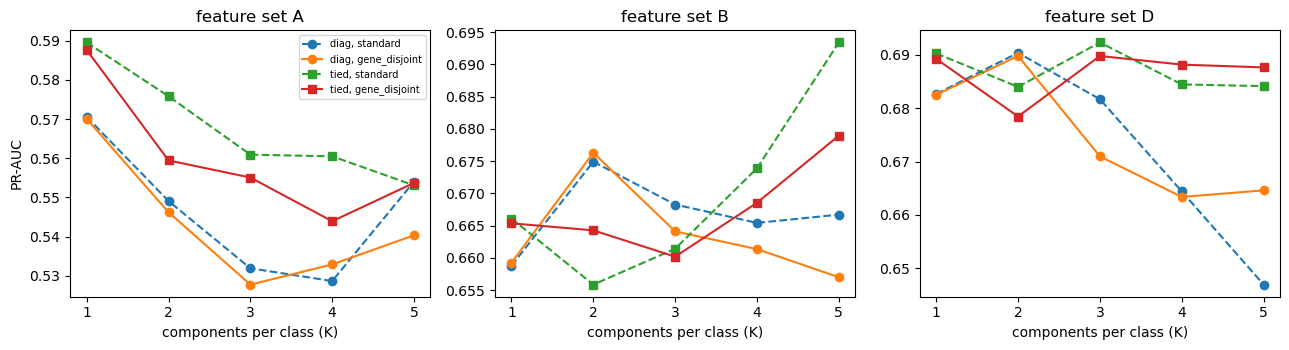

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=False)
for ax, fs in zip(axes, FEATURE_SETS):
    for cov_type, mk in [("diag", "o"), ("tied", "s")]:
        for s, ls in [("standard", "--"), ("gene_disjoint", "-")]:
            vals = [fixed_mean.loc[(s, fs, cov_type, K)] for K in K_GRID]
            ax.plot(K_GRID, vals, ls=ls, marker=mk, label=f"{cov_type}, {s}")
    ax.set_title(f"feature set {fs}")
    ax.set_xlabel("components per class (K)")
    ax.set_xticks(K_GRID)
axes[0].set_ylabel("PR-AUC")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.savefig(FIG_DIR / "components_covariance.png", dpi=150)
plt.show()

## 11. Statistics: paired differences, H1 and H2

Comparing feature sets. For each fold, I calculated the PR-AUC difference between two feature sets using the same test variants.

I used two types of intervals:
- Gene bootstrap: I resampled genes with replacement and recalculated the fold scores. The same resampled genes were used for all feature sets and validation schemes, so the comparisons remained paired.
- Corrected resampled t-test: This adjusts the variance because the training data overlap across folds.
Since H1 includes two comparisons, B versus A and D versus A, I used the Bonferroni-adjusted 97.5% confidence level.

In [18]:
def wap(y_sorted, w, ends):
    wy = w * y_sorted
    tp = np.cumsum(wy)[ends]
    total = np.cumsum(w)[ends]
    pos = tp[-1]
    if pos <= 0:
        return np.nan
    gain = np.diff(tp, prepend=0.0)
    return np.sum(gain * tp / np.maximum(total, 1e-12)) / pos


def build_items(scheme, fs):
    items = []
    for r in range(N_REPEATS):
        for f in range(N_SPLITS):
            res = results[(scheme, fs, r, f)]
            order = np.argsort(-res["score_mix"], kind="stable")
            s_sorted = res["score_mix"][order]
            ends = np.r_[np.where(np.diff(s_sorted) != 0)[0], len(s_sorted) - 1]
            items.append((res["y_test"][order], gene_codes[res["test_idx"]][order], ends))
    return items


def mean_wap(items, W):
    return np.mean([wap(yy, W[gg], ee) for yy, gg, ee in items])


items = {(s, fs): build_items(s, fs) for s in SCHEMES for fs in FEATURE_SETS}

res0 = results[("gene_disjoint", "A", 0, 0)]
yy0, gg0, ee0 = items[("gene_disjoint", "A")][0]
my_ap = wap(yy0, np.ones(len(yy0)), ee0)
sk_ap = average_precision_score(res0["y_test"], res0["score_mix"])
print("weighted AP:", round(my_ap, 6), "| sklearn:", round(sk_ap, 6))
assert abs(my_ap - sk_ap) < 1e-9

rng_boot = np.random.default_rng(SEED)
Ws = rng_boot.multinomial(G, np.full(G, 1.0 / G), size=N_BOOT)       # N_BOOT x G gene counts
ones = np.ones(G)

t0 = time.time()
boot = {}
point = {}
for s in SCHEMES:
    for fs in FEATURE_SETS:
        boot[(s, fs)] = np.array([mean_wap(items[(s, fs)], Ws[b]) for b in range(N_BOOT)])
        point[(s, fs)] = mean_wap(items[(s, fs)], ones)
print(f"bootstrap done in {time.time() - t0:.0f} seconds")

# check that the point estimates are the mean of the fold PR-AUC values
for s in SCHEMES:
    for fs in FEATURE_SETS:
        m = metrics_df[(metrics_df.model == "gmm_bic") & (metrics_df.validation == s) &
                       (metrics_df.feature_set == fs)]["pr_auc"].mean()
        assert abs(m - point[(s, fs)]) < 1e-8, (s, fs, m, point[(s, fs)])

weighted AP: 0.633931 | sklearn: 0.633931
bootstrap done in 12 seconds


In [19]:
def fold_pr(scheme, fs, table=None, model="gmm_bic"):
    table = metrics_df if table is None else table
    m = table[(table.model == model) & (table.validation == scheme) &
              (table.feature_set == fs)].sort_values(["repeat", "fold"])
    return m["pr_auc"].to_numpy()


def corrected_t(d, ratio, level):
    J = len(d)
    se = np.sqrt((1.0 / J + ratio) * d.var(ddof=1))
    tcrit = stats.t.ppf(1 - (1 - level) / 2, J - 1)
    t = d.mean() / se
    p = 2 * stats.t.sf(abs(t), J - 1)
    return d.mean() - tcrit * se, d.mean() + tcrit * se, t, p


def compare(scheme, a, b_, level=CI_LEVEL, boot_d=None, table=None, model="gmm_bic"):
    # paired difference b_ minus a for one validation scheme
    boot_d = boot if boot_d is None else boot_d
    d_boot = boot_d[(scheme, b_)] - boot_d[(scheme, a)]
    lo, hi = np.percentile(d_boot, [100 * (1 - level) / 2, 100 * (1 - (1 - level) / 2)])
    d_fold = fold_pr(scheme, b_, table, model) - fold_pr(scheme, a, table, model)
    ratio = fold_summary.loc[fold_summary.validation == scheme, "n_test"].mean() / \
            fold_summary.loc[fold_summary.validation == scheme, "n_train"].mean()
    t_lo, t_hi, t, p = corrected_t(d_fold, ratio, level)
    return {"validation": scheme, "comparison": f"{b_} vs {a}", "mean_diff_pr_auc": d_fold.mean(),
            "boot_lo": lo, "boot_hi": hi, "ttest_lo": t_lo, "ttest_hi": t_hi,
            "t": t, "p_unadjusted": p, "folds_better": int((d_fold > 0).sum()), "folds": len(d_fold)}


def verdict(row, lo_col="boot_lo", hi_col="boot_hi"):
    if row["mean_diff_pr_auc"] > 0 and row[lo_col] > 0:
        return "supported"
    if row[lo_col] <= 0 <= row[hi_col]:
        return "rejected (interval covers zero)"
    return "not supported (interval below zero)"


rows = [compare(s, "A", x) for s in SCHEMES for x in ["B", "D"]]
h1 = pd.DataFrame(rows)
h1["decision_bootstrap"] = h1.apply(verdict, axis=1)
h1["decision_ttest"] = h1.apply(lambda r: verdict(r, "ttest_lo", "ttest_hi"), axis=1)
h1.to_csv(OUT_DIR / "h1_all_comparisons.csv", index=False)
print(f"paired PR-AUC differences, {100 * CI_LEVEL:.1f}% intervals (Bonferroni for two comparisons)")
display(h1.round(4))

paired PR-AUC differences, 97.5% intervals (Bonferroni for two comparisons)


,validation,comparison,mean_diff_pr_auc,boot_lo,boot_hi,ttest_lo,ttest_hi,t,p_unadjusted,folds_better,folds,decision_bootstrap,decision_ttest
0,standard,B vs A,0.1127,0.0904,0.1346,0.0782,0.1472,8.1941,0.0000,15,15,supported,supported
1,standard,D vs A,0.0815,0.0608,0.1021,0.0271,0.1359,3.7569,0.0021,15,15,supported,supported
2,gene_disjoint,B vs A,0.1162,0.0969,0.1375,0.0437,0.1887,4.0220,0.0013,14,15,supported,supported
3,gene_disjoint,D vs A,0.1207,0.1032,0.1395,0.0658,0.1757,5.5129,0.0001,15,15,supported,supported


### H1 table (new genes)

H1 is tested using the gene-disjoint folds. It is supported when the average improvement of feature set B or D over A is greater than zero and the adjusted interval does not include zero. If the interval includes zero, H1 is rejected.

In [20]:
h1_new = h1[h1.validation == "gene_disjoint"].copy()
h1_table = h1_new[["comparison", "mean_diff_pr_auc", "boot_lo", "boot_hi", "ttest_lo", "ttest_hi",
                   "decision_bootstrap", "decision_ttest"]].reset_index(drop=True)
display(h1_table.round(4))
h1_table.to_csv(OUT_DIR / "h1_table.csv", index=False)

dec = h1_new["decision_bootstrap"].tolist()
if any(x == "supported" for x in dec):
    h1_final = "SUPPORTED (" + ", ".join(h1_new.loc[h1_new.decision_bootstrap == "supported", "comparison"]) + ")"
elif all(x.startswith("rejected") for x in dec):
    h1_final = "REJECTED (both intervals cover zero)"
else:
    h1_final = "NOT SUPPORTED (no improvement with an interval above zero, and not both intervals cover zero)"
print("H1 decision:", h1_final)

,comparison,mean_diff_pr_auc,boot_lo,boot_hi,ttest_lo,ttest_hi,decision_bootstrap,decision_ttest
0,B vs A,0.1162,0.0969,0.1375,0.0437,0.1887,supported,supported
1,D vs A,0.1207,0.1032,0.1395,0.0658,0.1757,supported,supported


H1 decision: SUPPORTED (B vs A, D vs A)


### H2 table (circular labelling)

H2 compares the gain of B over A on new genes with the gain on standard folds. It is only tested if the standard-fold gain is positive, otherwise it is reported as not testable. It is supported if the new-gene gain is under half of the standard gain and rejected if it is half or more.

In [21]:
gain_std = point[("standard", "B")] - point[("standard", "A")]
gain_new = point[("gene_disjoint", "B")] - point[("gene_disjoint", "A")]

if gain_std > 0:
    ratio = gain_new / gain_std
    h2_decision = "SUPPORTED (new-gene gain under half of the standard gain)" if ratio < H2_CUTOFF \
        else "REJECTED (new-gene gain is half of the standard gain or more)"
else:
    ratio = np.nan
    h2_decision = "NOT TESTABLE (standard-fold gain of B over A is not positive)"

bs = boot[("standard", "B")] - boot[("standard", "A")]
bn = boot[("gene_disjoint", "B")] - boot[("gene_disjoint", "A")]
ok = bs > 0
ratio_lo, ratio_hi = (np.percentile(bn[ok] / bs[ok], [2.5, 97.5]) if ok.sum() > 50 else (np.nan, np.nan))

h2_table = pd.DataFrame([{
    "gain_B_over_A_standard": gain_std, "gain_B_over_A_gene_disjoint": gain_new,
    "ratio_new_over_standard": ratio, "cutoff": H2_CUTOFF,
    "share_of_bootstrap_with_positive_standard_gain": ok.mean(),
    "ratio_boot_2.5": ratio_lo, "ratio_boot_97.5": ratio_hi, "decision": h2_decision}])
display(h2_table.round(4).T)
h2_table.to_csv(OUT_DIR / "h2_table.csv", index=False)
print("H2 decision:", h2_decision)

,0
gain_B_over_A_standard,0.1127
gain_B_over_A_gene_disjoint,0.1162
ratio_new_over_standard,1.0308
cutoff,0.5
share_of_bootstrap_with_positive_standard_gain,1.0
ratio_boot_2.5,0.9728
ratio_boot_97.5,1.1152
decision,REJECTED (new-gene gain is half of the standar...


H2 decision: REJECTED (new-gene gain is half of the standard gain or more)


### Drop on unseen genes with intervals, and D vs B

In [22]:
rows = []
for model_fs in FEATURE_SETS:
    d_boot = boot[("standard", model_fs)] - boot[("gene_disjoint", model_fs)]
    lo, hi = np.percentile(d_boot, [2.5, 97.5])
    rows.append({"feature_set": model_fs, "pr_auc_standard": point[("standard", model_fs)],
                 "pr_auc_gene_disjoint": point[("gene_disjoint", model_fs)],
                 "drop": point[("standard", model_fs)] - point[("gene_disjoint", model_fs)],
                 "boot_lo_95": lo, "boot_hi_95": hi})
drop_ci = pd.DataFrame(rows)
display(drop_ci.round(4))
drop_ci.to_csv(OUT_DIR / "drop_with_intervals.csv", index=False)

rows = []
for s in SCHEMES:
    d_boot = boot[(s, "D")] - boot[(s, "B")]
    lo, hi = np.percentile(d_boot, [2.5, 97.5])
    d_fold = fold_pr(s, "D") - fold_pr(s, "B")
    rows.append({"validation": s, "comparison": "D vs B", "mean_diff_pr_auc": d_fold.mean(),
                 "boot_lo_95": lo, "boot_hi_95": hi, "folds_better": int((d_fold > 0).sum()), "folds": len(d_fold)})
d_vs_b = pd.DataFrame(rows)
display(d_vs_b.round(4))
d_vs_b.to_csv(OUT_DIR / "d_vs_b_descriptive.csv", index=False)

,feature_set,pr_auc_standard,pr_auc_gene_disjoint,drop,boot_lo_95,boot_hi_95
0,A,0.5540,0.5408,0.0132,0.0043,0.0190
1,B,0.6667,0.6570,0.0097,-0.0004,0.0135
2,D,0.6355,0.6615,-0.0260,-0.0361,-0.0209


,validation,comparison,mean_diff_pr_auc,boot_lo_95,boot_hi_95,folds_better,folds
0,standard,D vs B,-0.0312,-0.0428,-0.0201,3,15
1,gene_disjoint,D vs B,0.0045,-0.0069,0.0151,8,15


## 12. Do a few very large genes drive the results?

I drop the largest genes from the evaluation (the models are not refitted, those genes are just left out when the held-out scores are counted) and look again at the PR-AUC and at the H1 differences on new genes.

In [23]:
order_genes = gene_size.index.tolist()
code_of = {g: i for i, g in enumerate(gene_names)}
rows = []
share = {}
for top in [0] + TOP_GENES:
    W = np.ones(G)
    drop_codes = [code_of[g] for g in order_genes[:top]]
    W[drop_codes] = 0.0
    share[top] = 1 - (gene_size.iloc[:top].sum() / len(df)) if top else 1.0
    pr = {fs: mean_wap(items[("gene_disjoint", fs)], W) for fs in FEATURE_SETS}
    rows.append({"largest genes removed": top, "variants kept": f"{share[top]:.1%}",
                 "PR-AUC A": pr["A"], "PR-AUC B": pr["B"], "PR-AUC D": pr["D"],
                 "B minus A": pr["B"] - pr["A"], "D minus A": pr["D"] - pr["A"]})
big_genes = pd.DataFrame(rows)
display(big_genes.round(4))
big_genes.to_csv(OUT_DIR / "large_gene_check.csv", index=False)
print("largest genes:", order_genes[:TOP_GENES[0]])

,largest genes removed,variants kept,PR-AUC A,PR-AUC B,PR-AUC D,B minus A,D minus A
0,0,100.0%,0.5408,0.6570,0.6615,0.1162,0.1207
1,10,88.8%,0.5748,0.7033,0.7082,0.1284,0.1334
2,25,81.7%,0.6076,0.7389,0.7419,0.1313,0.1343


largest genes: ['DNAH11', 'KMT2D', 'NEB', 'ADGRV1', 'SACS', 'DNAH5', 'COL7A1', 'ABCA4', 'ATRX', 'KMT2B']


## 13. Figures

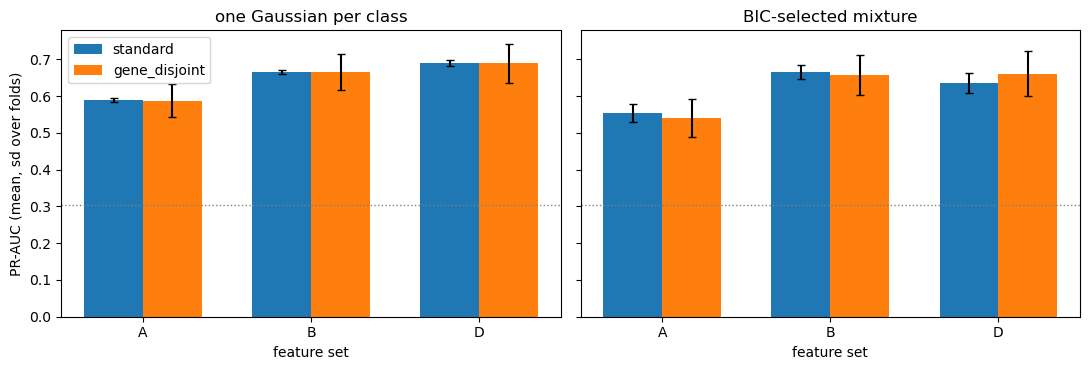

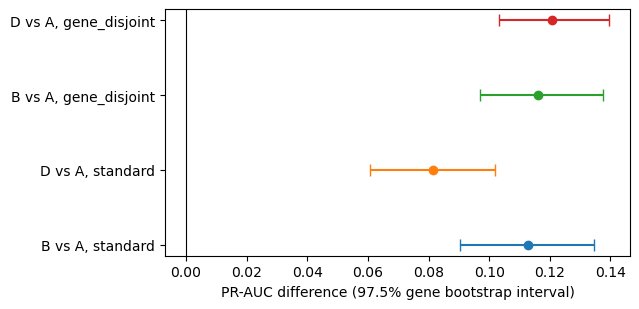

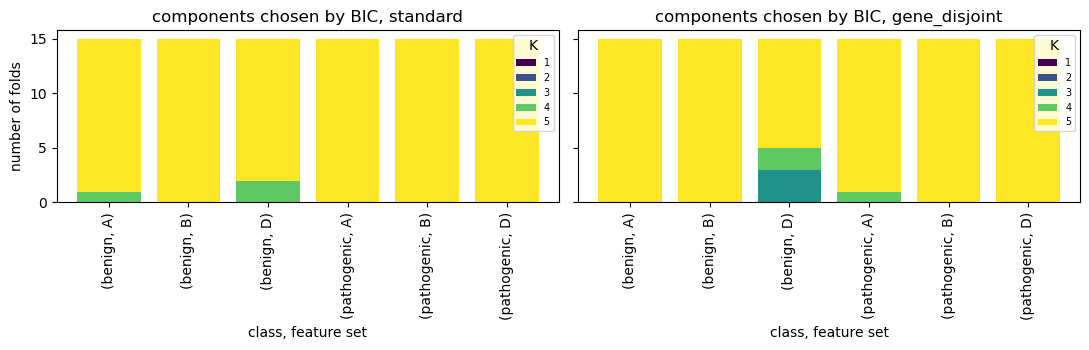

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
width = 0.35
for ax, model in zip(axes, ["gauss_1comp", "gmm_bic"]):
    for i, s in enumerate(SCHEMES):
        sub = metrics_df[(metrics_df.model == model) & (metrics_df.validation == s)]
        mu = sub.groupby("feature_set")["pr_auc"].mean().reindex(FEATURE_SETS)
        sd = sub.groupby("feature_set")["pr_auc"].std().reindex(FEATURE_SETS)
        ax.bar(np.arange(3) + (i - 0.5) * width, mu, width, yerr=sd, capsize=3, label=s)
    ax.axhline(y_all.mean(), color="grey", ls=":", lw=1)
    ax.set_xticks(range(3))
    ax.set_xticklabels(FEATURE_SETS)
    ax.set_xlabel("feature set")
    ax.set_title("one Gaussian per class" if model == "gauss_1comp" else "BIC-selected mixture")
axes[0].set_ylabel("PR-AUC (mean, sd over folds)")
axes[0].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "pr_auc_standard_vs_gene_disjoint.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 3.2))
labels, ypos = [], 0
for s in SCHEMES:
    for x in ["B", "D"]:
        r = h1[(h1.validation == s) & (h1.comparison == f"{x} vs A")].iloc[0]
        ax.errorbar(r["mean_diff_pr_auc"], ypos, xerr=[[r["mean_diff_pr_auc"] - r["boot_lo"]],
                    [r["boot_hi"] - r["mean_diff_pr_auc"]]], fmt="o", capsize=4)
        labels.append(f"{x} vs A, {s}")
        ypos += 1
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
ax.set_xlabel(f"PR-AUC difference ({100 * CI_LEVEL:.1f}% gene bootstrap interval)")
plt.tight_layout()
plt.savefig(FIG_DIR / "h1_differences.png", dpi=150)
plt.show()

kk = pd.crosstab([chosen["validation"], chosen["class"], chosen["feature_set"]], chosen["K"])
kk = kk.reindex(columns=K_GRID, fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, s in zip(axes, SCHEMES):
    sub = kk.loc[s]
    sub.plot(kind="bar", stacked=True, ax=ax, colormap="viridis", width=0.8)
    ax.set_title(f"components chosen by BIC, {s}")
    ax.set_xlabel("class, feature set")
    ax.legend(title="K", fontsize=7)
axes[0].set_ylabel("number of folds")
plt.tight_layout()
plt.savefig(FIG_DIR / "bic_choices.png", dpi=150)
plt.show()

## 14. Comparison with the team's models

In [25]:
TEAM_DIR = Path("team_predictions")
team_files = sorted(list(TEAM_DIR.glob("*.csv")) + list(TEAM_DIR.glob("*.csv.gz"))) if TEAM_DIR.exists() else []

if not team_files:
    print("no team prediction files found yet, so this comparison is skipped for now")
else:
    team = pd.concat([pd.read_csv(p) for p in team_files], ignore_index=True)
    need = {"model", "feature_set", "validation", "repeat", "fold", "label", "p_pathogenic"}
    assert need.issubset(team.columns), f"missing columns: {need - set(team.columns)}"
    rows = []
    for key, g in team.groupby(["model", "feature_set", "validation", "repeat", "fold"]):
        pred = g["pred_label"].to_numpy() if "pred_label" in g else (g["p_pathogenic"] >= 0.5).astype(int).to_numpy()
        rows.append(dict(zip(["model", "feature_set", "validation", "repeat", "fold"], key)) | {
            "roc_auc": roc_auc_score(g["label"], g["p_pathogenic"]),
            "pr_auc": average_precision_score(g["label"], g["p_pathogenic"]),
            "mcc": matthews_corrcoef(g["label"], pred), "acc": accuracy_score(g["label"], pred)})
    team_metrics = pd.DataFrame(rows)
    both = pd.concat([metrics_df[team_metrics.columns.intersection(metrics_df.columns)], team_metrics], ignore_index=True)
    comp = mean_sd_table(both)
    display(comp)
    comp.to_csv(OUT_DIR / "comparison_with_team.csv")

no team prediction files found yet, so this comparison is skipped for now


## 15. Exploratory improved pipeline

I first ran the pipeline described in my proposal and used those results for H1 and H2. After seeing the results, I tried another version because some features were highly skewed, bounded, or very similar to each other. I treat this as an additional analysis.

The model stayed the same, but I changed the preprocessing. I removed some raw frequency columns, filled missing frequency values, removed constant and highly correlated features, applied transformations, and standardized the data. The regularization and classification threshold were selected using only the training data.

Since some columns were removed, the feature sets in this analysis have fewer than 6, 15, and 28 features.

In [26]:
from sklearn.preprocessing import QuantileTransformer, PowerTransformer
from sklearn.linear_model import LogisticRegression

TRANSFORMS = ["quantile", "yeo-johnson"]
REG_GRID = [1e-3, 1e-2, 1e-1]
K_INNER = [1, 3, 5]
N_INIT_INNER = 2
RAW_AF = ["gnomADe_AF", "gnomADg_AF", "gnomAD_AF"]
MAX_RARITY = 8.0            # -log10(0 + 1e-8), used when the frequency is missing


def preprocess_v2(Xtr, Xev, cols, transform):
    cols = np.array(cols)
    keep = np.array([c not in RAW_AF for c in cols])
    Xtr, Xev, cols = Xtr[:, keep].copy(), Xev[:, keep].copy(), cols[keep]

    for j, c in enumerate(cols):                          # missing values
        if c.endswith("_neglog10"):
            fill = MAX_RARITY
        else:
            m = np.nanmedian(Xtr[:, j]) if np.isnan(Xtr[:, j]).any() else 0.0
            fill = 0.0 if np.isnan(m) else m
        Xtr[np.isnan(Xtr[:, j]), j] = fill
        Xev[np.isnan(Xev[:, j]), j] = fill

    keep = Xtr.std(0) > 1e-12                              # constant columns
    Xtr, Xev, cols = Xtr[:, keep], Xev[:, keep], cols[keep]

    corr = np.corrcoef(Xtr, rowvar=False)                  # near copies of an earlier column
    keep = np.ones(len(cols), dtype=bool)
    for j in range(len(cols)):
        if np.any(np.abs(corr[j, :j][keep[:j]]) > 0.999):
            keep[j] = False
    Xtr, Xev, cols = Xtr[:, keep], Xev[:, keep], cols[keep]

    cont = np.array([len(np.unique(Xtr[:, j])) > 10 for j in range(Xtr.shape[1])])
    if cont.any():
        if transform == "quantile":
            tf = QuantileTransformer(n_quantiles=min(1000, len(Xtr)), output_distribution="normal",
                                     subsample=200000, random_state=0)
        else:
            tf = PowerTransformer(method="yeo-johnson", standardize=False)
        Xtr[:, cont] = tf.fit_transform(Xtr[:, cont])
        Xev[:, cont] = tf.transform(Xev[:, cont])
    if not (np.isfinite(Xtr).all() and np.isfinite(Xev).all()):
        raise ValueError("non finite values after transform")

    mu, sd = Xtr.mean(0), Xtr.std(0)
    sd[sd < 1e-12] = 1.0
    return (Xtr - mu) / sd, (Xev - mu) / sd, list(cols)


def v2_scores(Xtr_raw, ytr, Xev_raw, cols, transform, reg, k_grid, n_init, seed_parts):
    Ztr, Zev, kept = preprocess_v2(Xtr_raw, Xev_raw, cols, transform)
    d = Ztr.shape[1]
    prior1 = ytr.mean()
    log_prior_ratio = np.log(prior1 / (1 - prior1))
    test_ll, rows = {}, []
    for c in (0, 1):
        Xc = Ztr[ytr == c]
        for ci, cov_type in enumerate(COV_TYPES):
            for K in k_grid:
                best, info = fit_mixture(Xc, K, cov_type, seed_parts + [c, ci, K], n_init=n_init, reg=reg)
                npar = n_params(K, d, cov_type)
                bic = -2 * info["ll"] * len(Xc) + npar * np.log(len(Xc))
                test_ll[(c, cov_type, K)] = mixture_logpdf(Zev, best, cov_type)
                rows.append({"cls": c, "cov": cov_type, "K": K, "n_params": npar, "loglik_mean": info["ll"],
                             "bic": bic, "n_iter": info["n_iter"], "converged": info["converged"],
                             "n_starts": info["n_starts"], "n_converged_starts": info["n_converged_starts"],
                             "ll_range": info["ll_range"], "selected": False})
    bic_df = pd.DataFrame(rows)
    sel = {}
    for c in (0, 1):
        sub = bic_df[bic_df["cls"] == c]
        i = sub["bic"].idxmin()
        bic_df.loc[i, "selected"] = True
        sel[c] = (bic_df.loc[i, "cov"], int(bic_df.loc[i, "K"]))
    s_mix = test_ll[(1,) + sel[1]] - test_ll[(0,) + sel[0]] + log_prior_ratio

    ll_one = []
    for c in (0, 1):
        mu, cov = fit_one_gaussian(Ztr[ytr == c], reg=reg)
        ll_one.append(one_gaussian_logpdf(Zev, mu, cov))
    s_one = ll_one[1] - ll_one[0] + log_prior_ratio
    return {"s_mix": s_mix, "s_one": s_one, "bic": bic_df, "sel": sel, "n_features": d, "kept": kept}


def best_threshold(y, s):
    cands = np.unique(np.percentile(s, np.linspace(1, 99, 99)))
    mccs = [matthews_corrcoef(y, (s > t).astype(int)) for t in cands]
    return float(cands[int(np.argmax(mccs))])


def platt(y, s):
    lr = LogisticRegression(C=1e6, max_iter=1000).fit(np.clip(s, -30, 30).reshape(-1, 1), y)
    return float(lr.coef_[0, 0]), float(lr.intercept_[0])


def run_fold_v2_inner(job):
    t_start = time.time()
    X, y, tr, te, cols = job["X"], job["y"], job["train"], job["test"], job["cols"]
    Xtr_raw, ytr = X[tr], y[tr]
    base = [SEED + 1000, job["scheme_id"], job["fs_id"], job["repeat"], job["fold"]]

    # inner split of the training fold, same type as the outer scheme
    inner_seed = SEED + 100 + 10 * job["repeat"] + job["fold"]
    if job["scheme"] == "standard":
        sp = StratifiedKFold(n_splits=5, shuffle=True, random_state=inner_seed).split(np.zeros(len(tr)), ytr)
    else:
        sp = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=inner_seed).split(
            np.zeros(len(tr)), ytr, gene_codes[tr])
    itr, iva = next(iter(sp))

    tune_rows, best = [], None
    for ti, tf in enumerate(TRANSFORMS):
        for ri, reg in enumerate(REG_GRID):
            try:
                o = v2_scores(Xtr_raw[itr], ytr[itr], Xtr_raw[iva], cols, tf, reg, K_INNER, N_INIT_INNER,
                              base + [0, ti, ri])
                pr = average_precision_score(ytr[iva], o["s_mix"])
            except (np.linalg.LinAlgError, ValueError):
                o, pr = None, -1.0
            tune_rows.append({"transform": tf, "reg_covar": reg, "inner_pr_auc": pr})
            if o is not None and (best is None or pr > best["pr"]):
                best = {"pr": pr, "tf": tf, "reg": reg, "o": o}
    s_val_mix, s_val_one, y_val = best["o"]["s_mix"], best["o"]["s_one"], ytr[iva]
    thr_mix, thr_one = best_threshold(y_val, s_val_mix), best_threshold(y_val, s_val_one)
    pa_mix, pb_mix = platt(y_val, s_val_mix)
    pa_one, pb_one = platt(y_val, s_val_one)

    fin = v2_scores(Xtr_raw, ytr, X[te], cols, best["tf"], best["reg"], K_GRID, N_INIT, base + [1, 0, 0])
    return {"scheme": job["scheme"], "fs": job["fs"], "repeat": job["repeat"], "fold": job["fold"],
            "test_idx": te, "y_test": y[te], "score_mix": fin["s_mix"], "score_one": fin["s_one"],
            "thr_mix": thr_mix, "thr_one": thr_one,
            "platt_mix": (pa_mix, pb_mix), "platt_one": (pa_one, pb_one),
            "transform": best["tf"], "reg": best["reg"], "n_features": fin["n_features"],
            "kept": fin["kept"], "tuning": pd.DataFrame(tune_rows), "bic": fin["bic"],
            "sel0": fin["sel"][0], "sel1": fin["sel"][1], "seconds": time.time() - t_start}


SETTINGS_TAG2 = hashlib.md5(json.dumps([SETTINGS_TAG, TRANSFORMS, REG_GRID, K_INNER, N_INIT_INNER,
                                        "v2"]).encode()).hexdigest()[:8]


def run_fold_v2(job):
    cache_file = CACHE_DIR / f"v2_{SETTINGS_TAG2}_{job['scheme']}_{job['fs']}_r{job['repeat']}_f{job['fold']}.pkl"
    if cache_file.exists():
        return joblib.load(cache_file)
    with threadpool_limits(limits=1):
        out = run_fold_v2_inner(job)
    joblib.dump(out, cache_file)
    return out

In [27]:
def make_job_v2(scheme, fs, fd):
    j = make_job(scheme, fs, fd)
    j["cols"] = feature_sets[fs]
    return j


t0 = time.time()
test_v2 = run_fold_v2_inner(make_job_v2("gene_disjoint", "D", folds["gene_disjoint"][0]))
print(f"one fold, set D, gene-disjoint: {time.time() - t0:.1f} seconds")
print("chosen transform:", test_v2["transform"], "| reg_covar:", test_v2["reg"],
      "| BIC choice benign:", test_v2["sel0"], "pathogenic:", test_v2["sel1"])
print("columns kept:", test_v2["n_features"], "of 28")
display(test_v2["tuning"].round(4))

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


one fold, set D, gene-disjoint: 16.2 seconds
chosen transform: yeo-johnson | reg_covar: 0.01 | BIC choice benign: ('tied', 5) pathogenic: ('tied', 5)
columns kept: 24 of 28


,transform,reg_covar,inner_pr_auc
0,quantile,0.001,0.4774
1,quantile,0.010,0.4853
2,quantile,0.100,0.5431
3,yeo-johnson,0.001,0.5336
4,yeo-johnson,0.010,0.6165
5,yeo-johnson,0.100,0.5893


Now all 90 fold runs for the exploratory pipeline.

In [28]:
jobs_v2 = [make_job_v2(s, fs, fd) for s in SCHEMES for fs in FEATURE_SETS for fd in folds[s]]
t_all = time.time()
out_v2 = Parallel(n_jobs=N_JOBS, verbose=5)(delayed(run_fold_v2)(j) for j in jobs_v2)
print(f"done, wall time of this run: {(time.time() - t_all) / 60:.1f} minutes")
results_v2 = {(r["scheme"], r["fs"], r["repeat"], r["fold"]): r for r in out_v2}

[Parallel(n_jobs=10)]: Using backend LokyBackend with 10 concurrent workers.


done, wall time of this run: 0.0 minutes


[Parallel(n_jobs=10)]: Done  71 out of  90 | elapsed:    0.3s remaining:    0.1s
[Parallel(n_jobs=10)]: Done  90 out of  90 | elapsed:    0.3s finished


### Results of the exploratory pipeline

In [29]:
MODELS_V2 = {"gmm_bic_v2": ("score_mix", "thr_mix", "platt_mix"), "gauss_1comp_v2": ("score_one", "thr_one", "platt_one")}

rows, pred_parts = [], []
for (scheme, fs, r, f), res in results_v2.items():
    for model, (skey, tkey, pkey) in MODELS_V2.items():
        s, thr = res[skey], res[tkey]
        base_m = get_metrics(res["y_test"], s)                       # threshold 0
        pred = (s > thr).astype(int)
        tuned_m = get_metrics(res["y_test"], s, threshold=thr)
        rows.append({"validation": scheme, "feature_set": fs, "repeat": r, "fold": f, "model": model,
                     "n_test": len(s), "roc_auc": base_m["roc_auc"], "pr_auc": base_m["pr_auc"],
                     "mcc": tuned_m["mcc"], "acc": tuned_m["acc"],
                     "balanced_acc": tuned_m["balanced_acc"],
                     "precision_pathogenic": tuned_m["precision_pathogenic"],
                     "recall_pathogenic": tuned_m["recall_pathogenic"],
                     "specificity_benign": tuned_m["specificity_benign"],
                     "f1_pathogenic": tuned_m["f1_pathogenic"],
                     "true_benign": tuned_m["true_benign"],
                     "false_pathogenic": tuned_m["false_pathogenic"],
                     "false_benign": tuned_m["false_benign"],
                     "true_pathogenic": tuned_m["true_pathogenic"],
                     "mcc_t0": base_m["mcc"], "acc_t0": base_m["acc"], "threshold": thr,
                     "transform": res["transform"], "reg_covar": res["reg"], "n_features": res["n_features"]})
        a, b0 = res[pkey]
        pred_parts.append(pd.DataFrame({
            "model": model, "feature_set": fs, "validation": scheme, "repeat": r, "fold": f,
            "VariationID": vid[res["test_idx"]], "GeneSymbol": gsym[res["test_idx"]],
            "label": res["y_test"], "log_odds": s, "p_pathogenic": expit(a * np.clip(s, -30, 30) + b0),
            "pred_label": pred}))
metrics_v2 = pd.DataFrame(rows).sort_values(["validation", "model", "feature_set", "repeat", "fold"]).reset_index(drop=True)
metrics_v2.to_csv(OUT_DIR / "v2_metrics_by_fold.csv", index=False)
pd.concat(pred_parts, ignore_index=True).to_csv(OUT_DIR / "predictions_gmm_v2.csv.gz", index=False, compression="gzip")

both = pd.concat([metrics_df, metrics_v2[metrics_df.columns]], ignore_index=True)
cmp_table = mean_sd_table(both)
cmp_table.to_csv(OUT_DIR / "v2_vs_original_main_results.csv")
display(cmp_table)

# what the folds chose
print("transform chosen (number of folds):")
display(metrics_v2[metrics_v2.model == "gmm_bic_v2"].groupby(["validation", "feature_set", "transform"]).size().unstack(fill_value=0))
print("reg_covar chosen (number of folds):")
display(metrics_v2[metrics_v2.model == "gmm_bic_v2"].groupby(["validation", "feature_set", "reg_covar"]).size().unstack(fill_value=0))
print("columns kept per feature set:", metrics_v2.groupby("feature_set")["n_features"].agg(["min", "max"]).to_dict("index"))

roc_auc           pr_auc              mcc              acc     balanced_acc precision_pathogenic recall_pathogenic specificity_benign  \
validation    model          feature_set                                                                                                                                                  
gene_disjoint gauss_1comp    A            0.796 +/- 0.012  0.588 +/- 0.045  0.371 +/- 0.025  0.617 +/- 0.025   0.696 +/- 0.01      0.437 +/- 0.043    0.897 +/- 0.01    0.494 +/- 0.023   
                             B            0.845 +/- 0.011   0.665 +/- 0.05  0.434 +/- 0.036  0.654 +/- 0.031  0.731 +/- 0.014       0.467 +/- 0.05   0.925 +/- 0.009     0.537 +/- 0.03   
                             D            0.863 +/- 0.012  0.689 +/- 0.053  0.476 +/- 0.034  0.691 +/- 0.028  0.756 +/- 0.012      0.497 +/- 0.051   0.923 +/- 0.008     0.59 +/- 0.028   
              gauss_1comp_v2 A            0.797 +/- 0.013  0.589 +/- 0.047  0.429 +/- 0.028  0.745 +/- 0.012  0.722 +/- 0.017      0.573 +/- 0.054   0.662 +/- 0.067    0.783 +/- 0.041   
                             B            0.844 +/- 0.013  0.661 +/- 0.053  0.507 +/- 0.035  0.771 +/- 0.025  0.767 +/- 0.013      0.604 +/- 0.067   0.754 +/- 0.053     0.78 +/- 0.052   
                             D            0.864 +/- 0.012  0.691 +/- 0.052  0.548 +/- 0.032   0.791 +/- 0.02  0.788 +/- 0.014      0.633 +/- 0.068   0.775 +/- 0.056    0.801 +/- 0.046   
              gmm_bic        A             0.759 +/- 0.02  0.541 +/- 0.052  0.348 +/- 0.058  0.688 +/- 0.046  0.685 +/- 0.025      0.499 +/- 0.074   0.673 +/- 0.037    0.696 +/- 0.077   
                             B            0.823 +/- 0.023  0.657 +/- 0.054  0.439 +/- 0.044  0.677 +/- 0.039  0.736 +/- 0.019      0.487 +/- 0.061   0.885 +/- 0.042     0.588 +/- 0.06   
                             D            0.837 +/- 0.018  0.662 +/- 0.061  0.473 +/- 0.042  0.722 +/- 0.036  0.755 +/- 0.019       0.53 +/- 0.058   0.843 +/- 0.045    0.668 +/- 0.066   
              gmm_bic_v2     A            0.774 +/- 0.018  0.554 +/- 0.046  0.379 +/- 0.087  0.723 +/- 0.023  0.698 +/- 0.051      0.535 +/- 0.053   0.637 +/- 0.161    0.758 +/- 0.076   
                             B            0.843 +/- 0.015  0.694 +/- 0.055  0.489 +/- 0.041  0.759 +/- 0.037  0.755 +/- 0.017      0.597 +/- 0.092    0.74 +/- 0.095    0.771 +/- 0.089   
                             D            0.853 +/- 0.014  0.683 +/- 0.062  0.519 +/- 0.046  0.772 +/- 0.025   0.773 +/- 0.03      0.606 +/- 0.073   0.772 +/- 0.109    0.774 +/- 0.069   
standard      gauss_1comp    A            0.797 +/- 0.005   0.59 +/- 0.006  0.371 +/- 0.007  0.616 +/- 0.004  0.695 +/- 0.004      0.436 +/- 0.003   0.897 +/- 0.005    0.493 +/- 0.006   
                             B            0.845 +/- 0.003  0.666 +/- 0.006  0.433 +/- 0.006  0.653 +/- 0.004   0.73 +/- 0.004      0.465 +/- 0.003   0.925 +/- 0.004    0.535 +/- 0.006   
                             D            0.863 +/- 0.003   0.69 +/- 0.007  0.475 +/- 0.005  0.691 +/- 0.004  0.756 +/- 0.003      0.496 +/- 0.003   0.923 +/- 0.004    0.589 +/- 0.006   
              gauss_1comp_v2 A            0.799 +/- 0.006  0.593 +/- 0.008  0.439 +/- 0.013  0.747 +/- 0.009  0.729 +/- 0.008      0.571 +/- 0.016   0.684 +/- 0.034    0.775 +/- 0.024   
                             B            0.845 +/- 0.003  0.665 +/- 0.007   0.51 +/- 0.007  0.774 +/- 0.008  0.768 +/- 0.006      0.604 +/- 0.019   0.755 +/- 0.037    0.782 +/- 0.027   
                             D            0.865 +/- 0.005  0.693 +/- 0.012   0.556 +/- 0.01  0.793 +/- 0.009  0.794 +/- 0.006      0.626 +/- 0.019   0.798 +/- 0.033     0.79 +/- 0.025   
              gmm_bic        A            0.774 +/- 0.017  0.554 +/- 0.024  0.397 +/- 0.035  0.729 +/- 0.028  0.706 +/- 0.016       0.55 +/- 0.041   0.647 +/- 0.041    0.765 +/- 0.053   
                             B             0.83 +/- 0.012  0.667 +/- 0.019  0.432 +/- 0.015  0.668 +/- 0.031  0.731 +/- 0.0

transform chosen (number of folds):


transform                  quantile  yeo-johnson
validation    feature_set                       
gene_disjoint A                   2           13
              B                   1           14
              D                   2           13
standard      A                   1           14
              B                   0           15
              D                   1           14

reg_covar chosen (number of folds):


reg_covar                  0.001  0.010  0.100
validation    feature_set                     
gene_disjoint A                3      3      9
              B                2      0     13
              D                1      8      6
standard      A                2      3     10
              B                2      2     11
              D                0      9      6

columns kept per feature set: {'A': {'min': 6, 'max': 6}, 'B': {'min': 11, 'max': 11}, 'D': {'min': 24, 'max': 24}}


In [30]:
bic_v2 = pd.concat([r["bic"].assign(validation=k[0], feature_set=k[1], repeat=k[2], fold=k[3])
                    for k, r in results_v2.items()], ignore_index=True)
bic_v2["class"] = bic_v2["cls"].map({0: "benign", 1: "pathogenic"})
bic_v2.to_csv(OUT_DIR / "v2_bic_records.csv", index=False)
chosen_v2 = bic_v2[bic_v2["selected"]]
print("chosen K, exploratory pipeline")
display(pd.crosstab([chosen_v2["validation"], chosen_v2["feature_set"], chosen_v2["class"]], chosen_v2["K"]))
print("chosen covariance type, exploratory pipeline")
display(pd.crosstab([chosen_v2["validation"], chosen_v2["feature_set"], chosen_v2["class"]], chosen_v2["cov"]))
print("fits where the best start did not converge:", int((~bic_v2["converged"]).sum()), "of", len(bic_v2))

chosen K, exploratory pipeline


K                                     3  4   5
validation    feature_set class               
gene_disjoint A           benign      0  1  14
                          pathogenic  0  0  15
              B           benign      0  3  12
                          pathogenic  0  0  15
              D           benign      0  5  10
                          pathogenic  0  2  13
standard      A           benign      0  0  15
                          pathogenic  0  0  15
              B           benign      0  3  12
                          pathogenic  0  0  15
              D           benign      0  3  12
                          pathogenic  1  4  10

chosen covariance type, exploratory pipeline


cov                                   diag  tied
validation    feature_set class                 
gene_disjoint A           benign        15     0
                          pathogenic    15     0
              B           benign         0    15
                          pathogenic     2    13
              D           benign         1    14
                          pathogenic     1    14
standard      A           benign        15     0
                          pathogenic    15     0
              B           benign         2    13
                          pathogenic     4    11
              D           benign         0    15
                          pathogenic     1    14

fits where the best start did not converge: 0 of 1800


### Gain over the original pipeline, with intervals

I compared the PR-AUC from the exploratory BIC mixture with the original BIC mixture. The difference was calculated using the same resampled genes, so the comparison stayed paired. I made the same comparison for the one-component Gaussian model. The intervals are 95% gene-bootstrap intervals.

In [31]:
def build_items_v2(scheme, fs, key):
    out = []
    for r in range(N_REPEATS):
        for f in range(N_SPLITS):
            res = results_v2[(scheme, fs, r, f)]
            order = np.argsort(-res[key], kind="stable")
            s_sorted = res[key][order]
            ends = np.r_[np.where(np.diff(s_sorted) != 0)[0], len(s_sorted) - 1]
            out.append((res["y_test"][order], gene_codes[res["test_idx"]][order], ends))
    return out


def build_items_orig_one(scheme, fs):
    out = []
    for r in range(N_REPEATS):
        for f in range(N_SPLITS):
            res = results[(scheme, fs, r, f)]
            order = np.argsort(-res["score_one"], kind="stable")
            s_sorted = res["score_one"][order]
            ends = np.r_[np.where(np.diff(s_sorted) != 0)[0], len(s_sorted) - 1]
            out.append((res["y_test"][order], gene_codes[res["test_idx"]][order], ends))
    return out


boot_v2, boot_v2_one, boot_o_one = {}, {}, {}
for s in SCHEMES:
    for fs in FEATURE_SETS:
        it_m, it_o, it_oo = build_items_v2(s, fs, "score_mix"), build_items_v2(s, fs, "score_one"), build_items_orig_one(s, fs)
        boot_v2[(s, fs)] = np.array([mean_wap(it_m, Ws[b]) for b in range(N_BOOT)])
        boot_v2_one[(s, fs)] = np.array([mean_wap(it_o, Ws[b]) for b in range(N_BOOT)])
        boot_o_one[(s, fs)] = np.array([mean_wap(it_oo, Ws[b]) for b in range(N_BOOT)])

rows = []
for s in SCHEMES:
    for fs in FEATURE_SETS:
        for name, new, old in [("BIC mixture", boot_v2[(s, fs)], boot[(s, fs)]),
                               ("one Gaussian per class", boot_v2_one[(s, fs)], boot_o_one[(s, fs)])]:
            d = new - old
            lo, hi = np.percentile(d, [2.5, 97.5])
            rows.append({"validation": s, "feature_set": fs, "model": name, "pr_auc_original": old.mean(),
                         "pr_auc_exploratory": new.mean(), "gain": d.mean(), "boot_lo_95": lo, "boot_hi_95": hi})
gain = pd.DataFrame(rows)
display(gain.round(4))
gain.to_csv(OUT_DIR / "v2_gain_over_original.csv", index=False)

,validation,feature_set,model,pr_auc_original,pr_auc_exploratory,gain,boot_lo_95,boot_hi_95
0,standard,A,BIC mixture,0.5551,0.5673,0.0122,0.0065,0.0178
1,standard,A,one Gaussian per class,0.5907,0.5946,0.0039,-0.0021,0.0101
2,standard,B,BIC mixture,0.6672,0.6919,0.0247,0.0185,0.0308
3,standard,B,one Gaussian per class,0.6670,0.6657,-0.0013,-0.0041,0.0018
4,standard,D,BIC mixture,0.6360,0.6951,0.0590,0.0530,0.0656
5,standard,D,one Gaussian per class,0.6909,0.6931,0.0022,-0.0006,0.0051
6,gene_disjoint,A,BIC mixture,0.5434,0.5565,0.0131,0.0061,0.0202
7,gene_disjoint,A,one Gaussian per class,0.5901,0.5913,0.0012,-0.0040,0.0070
8,gene_disjoint,B,BIC mixture,0.6598,0.6968,0.0370,0.0305,0.0438
9,gene_disjoint,B,one Gaussian per class,0.6686,0.6645,-0.0042,-0.0072,-0.0012


### H1 and H2 again, on the exploratory pipeline (sensitivity only)

I repeated H1 and H2 using the updated preprocessing. I kept the same rules and cutoffs. The results from Section 11 are still the official ones.

In [32]:
rows = [compare(s, "A", x, boot_d=boot_v2, table=metrics_v2, model="gmm_bic_v2") for s in SCHEMES for x in ["B", "D"]]
h1_v2 = pd.DataFrame(rows)
h1_v2["decision_bootstrap"] = h1_v2.apply(verdict, axis=1)
h1_v2["decision_ttest"] = h1_v2.apply(lambda r: verdict(r, "ttest_lo", "ttest_hi"), axis=1)
display(h1_v2.round(4))
h1_v2.to_csv(OUT_DIR / "v2_h1_all_comparisons.csv", index=False)

g_std = boot_v2[("standard", "B")].mean() - boot_v2[("standard", "A")].mean()
g_new = boot_v2[("gene_disjoint", "B")].mean() - boot_v2[("gene_disjoint", "A")].mean()
if g_std > 0:
    ratio_v2 = g_new / g_std
    h2_v2 = "supported" if ratio_v2 < H2_CUTOFF else "rejected"
else:
    ratio_v2, h2_v2 = np.nan, "not testable"
print(f"H2 (exploratory): gain standard {g_std:.4f}, gain new genes {g_new:.4f}, ratio {ratio_v2:.3f} -> {h2_v2}")
pd.DataFrame([{"gain_standard": g_std, "gain_gene_disjoint": g_new, "ratio": ratio_v2, "decision": h2_v2}]).to_csv(
    OUT_DIR / "v2_h2_table.csv", index=False)

drop_v2 = pd.DataFrame([{"feature_set": fs,
                         "pr_auc_standard": boot_v2[("standard", fs)].mean(),
                         "pr_auc_gene_disjoint": boot_v2[("gene_disjoint", fs)].mean(),
                         "drop": boot_v2[("standard", fs)].mean() - boot_v2[("gene_disjoint", fs)].mean()}
                        for fs in FEATURE_SETS])
print("drop on unseen genes, exploratory BIC mixture:")
display(drop_v2.round(4))

,validation,comparison,mean_diff_pr_auc,boot_lo,boot_hi,ttest_lo,ttest_hi,t,p_unadjusted,folds_better,folds,decision_bootstrap,decision_ttest
0,standard,B vs A,0.1250,0.1076,0.1426,0.0650,0.1850,5.2305,0.0001,14,15,supported,supported
1,standard,D vs A,0.1282,0.1075,0.1492,0.0619,0.1946,4.8490,0.0003,14,15,supported,supported
2,gene_disjoint,B vs A,0.1402,0.1231,0.1591,0.0992,0.1812,8.5841,0.0000,15,15,supported,supported
3,gene_disjoint,D vs A,0.1290,0.1098,0.1498,0.0801,0.1778,6.6278,0.0000,15,15,supported,supported


H2 (exploratory): gain standard 0.1246, gain new genes 0.1403, ratio 1.126 -> rejected
drop on unseen genes, exploratory BIC mixture:


,feature_set,pr_auc_standard,pr_auc_gene_disjoint,drop
0,A,0.5673,0.5565,0.0108
1,B,0.6919,0.6968,-0.0049
2,D,0.6951,0.6853,0.0098


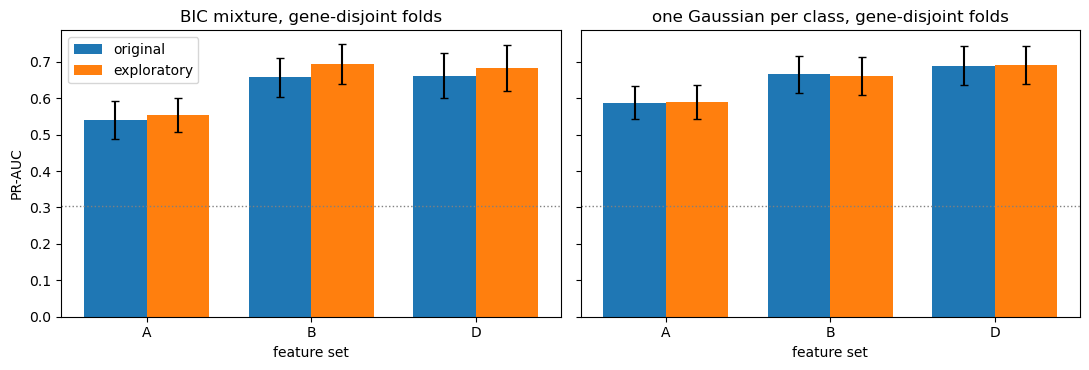

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
w = 0.38
for ax, (title, o_model, n_model) in zip(axes, [("BIC mixture", "gmm_bic", "gmm_bic_v2"),
                                                ("one Gaussian per class", "gauss_1comp", "gauss_1comp_v2")]):
    for i, (lab, tab, mdl) in enumerate([("original", metrics_df, o_model), ("exploratory", metrics_v2, n_model)]):
        sub = tab[(tab.model == mdl) & (tab.validation == "gene_disjoint")]
        mu = sub.groupby("feature_set")["pr_auc"].mean().reindex(FEATURE_SETS)
        sd = sub.groupby("feature_set")["pr_auc"].std().reindex(FEATURE_SETS)
        ax.bar(np.arange(3) + (i - 0.5) * w, mu, w, yerr=sd, capsize=3, label=lab)
    ax.axhline(y_all.mean(), color="grey", ls=":", lw=1)
    ax.set_xticks(range(3))
    ax.set_xticklabels(FEATURE_SETS)
    ax.set_xlabel("feature set")
    ax.set_title(title + ", gene-disjoint folds")
axes[0].set_ylabel("PR-AUC")
axes[0].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "original_vs_exploratory.png", dpi=150)
plt.show()

## 16. Files saved

In [34]:
saved = sorted(p.name for p in OUT_DIR.glob("*") if p.is_file())
print("files in", OUT_DIR, ":")
for name in saved:
    print("  ", name)

print()
print("python", platform.python_version(), "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("settings: folds", N_SPLITS, "x", N_REPEATS, "| K", K_GRID, "| covariance", COV_TYPES,
      "| starts", N_INIT, "| max_iter", MAX_ITER, "| tol", TOL, "| reg_covar", REG_COVAR, "| seed", SEED)

files in results :
   .DS_Store
   bic_records.csv
   chosen_K.csv
   chosen_cov.csv
   component_covariance_comparison.csv
   d_vs_b_descriptive.csv
   drop_with_intervals.csv
   fixed_setting_metrics.csv
   fold_assignments.csv
   fold_summary.csv
   h1_all_comparisons.csv
   h1_table.csv
   h2_table.csv
   large_gene_check.csv
   main_results.csv
   metrics_by_fold.csv
   performance_drop.csv
   predictions_gmm.csv.gz
   predictions_gmm_v2.csv.gz
   runtime_by_fold.csv
   selected_settings.csv
   stability_summary.csv
   v2_bic_records.csv
   v2_gain_over_original.csv
   v2_h1_all_comparisons.csv
   v2_h2_table.csv
   v2_metrics_by_fold.csv
   v2_vs_original_main_results.csv

python 3.13.15 | numpy 2.4.6 | scikit-learn 1.6.1
settings: folds 5 x 3 | K [1, 2, 3, 4, 5] | covariance ['diag', 'tied'] | starts 5 | max_iter 200 | tol 0.0001 | reg_covar 0.001 | seed 8
